<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/30_QML_Defences_Against_ML_Attacks/QRNN_AdversarialAttackFL_Venkat2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QRNN for adversarial-attack detection in federated learning: Venkat et al. (2026) step by step

**Paper.** R. Venkat, M. Prakash, R. R. Immanuel, K. S. Kumar, N. Duraimutharasan, S. Balasubramaniam, T. A. Sivakumar, *Adversarial Attack Detection in Federated Learning Using Quantum Recurrent Neural Network*, Applied Computational Intelligence and Soft Computing, vol. 2026, article 1176614. DOI: [10.1155/acis/1176614](https://doi.org/10.1155/acis/1176614).

**What this notebook does.** The paper proposes a *dollmaker weighted moving average quantum recurrent neural network* (DWMA_QRNN): several clients each train a quantum recurrent network on their own network-traffic data, a server averages the clients' weights (federated learning, FL), and the quantum network is trained with a population-based optimiser that mixes the Dollmaker Optimization Algorithm (DOA) with an exponentially weighted moving average (EWMA). It reports about 90 % accuracy on the N-BaIoT botnet data and 8 to 13 points more than nine classical baselines. We rebuild every ingredient from scratch with a plain-language explanation of each step: the real N-BaIoT traffic is downloaded and sampled in time order, nine IoT devices become nine FL clients, an 8-qubit recurrent circuit is written in PennyLane and simulated exactly, the DWMA optimiser is implemented from the paper's equations, and we compare it with Adam, with a classical federated LSTM, with a random forest and with an RBF support-vector machine on exactly the same inputs. The notebook then checks the paper's numbers one by one.

**How to run it.** Open in Google Colab, keep the normal CPU runtime (no GPU, no account, no quantum hardware), choose *Runtime, then Run all*. The first run downloads the public N-BaIoT archive (1.7 GB) and samples it, which takes about 10 to 15 minutes on Colab; the sampled windows are cached in `DATA_DIR`, so later runs skip the download. `FAST_MODE = True` (default, set in the configuration cell) is a class demo for the training part: it took 12 minutes (after the data cache existed; 19 minutes on the same laptop while it was heavily loaded) on one CPU thread, plus 10 to 15 minutes for the one-time download and sampling of the data. `FAST_MODE = False` uses the larger budgets listed in the configuration cell (10 rounds, 3 seeds, full sweeps, two population sizes); we estimate 2 to 3 hours on the same machine and did **not** run it for the outputs stored in this notebook.

**What you get at the end.** The data exploration (shape, 115 features, the 11 real traffic classes, 2-D projections of real observations coloured by their true label), the drawing of the circuit that is actually executed, a federated training run for each optimiser, the paper's accuracy / loss / normalised-MSE comparison redrawn with our numbers, one verdict per paper claim, a critical reading of the paper and five exercises.

## The paper in one page

* **Problem.** In a federated setting an attacker can manipulate data or model updates ("adversarial attacks") and fool the global model. The authors want a detector that works across distributed IoT nodes. In the experiments "adversarial attack" simply means *malicious IoT botnet traffic* (Mirai and BASHLITE) versus benign traffic: the paper never crafts adversarial examples (no FGSM, no PGD), even though the manifest of this repository lists them for the topic.
* **Decision.** Binary: attack or not attack (Table 1: output size 2, cross-entropy loss).
* **Federated learning.** A central server and several client nodes. Each epoch every client trains on its local data and sends its parameters to the server, which averages them (the paper calls this "the average method" and writes the two clients' weights as alpha_1 and alpha_2) and sends the result back. Figure 1 draws "intruders" sending perturbed updates but no experiment studies them.
* **Model.** Min-max normalisation, then a quantum recurrent neural network (QRNN, after Takaki et al.): a hidden register H and a data register D, a parametrised ansatz applied at every time step, measurement of the registers (Figure 3). Table 1: 8 qubits, "BitFlip + QuantumNeuron + Unitary" gates, hidden size 16, tanh, dropout 0.2, sequence length 100, batch 64, learning rate 0.001, 100 epochs, cross-entropy, PyTorch, CPU only.
* **Optimiser (DWMA).** Dolls are candidate parameter vectors. Exploration ("pattern selection and sewing", eq. 9) moves a doll towards a randomly chosen pattern; exploitation ("beautifying the details", eq. 17) makes small steps that shrink with the iteration counter; a candidate replaces the old position only if the fitness (the mean squared error of eq. 7) improves (eqs. 16, 18). EWMA (eqs. 13 to 15) smooths the trajectory.
* **Data.** Dataset 1: a Mirai DDoS capture (35 pcapng traffic samples) from a data portal. Dataset 2: N-BaIoT, 7,062,606 instances of 115 real-valued attributes from nine commercial IoT devices infected by Mirai and BASHLITE.
* **Claims (Dataset 2).** Table 2 and Figures 6 to 9: accuracy 90.06 % at 90 % training data and 90.23 % at time step 100; loss 0.099 and 0.098; normalised MSE 0.090 and 0.099; nine baselines between 78.02 % and 86.74 % (LSTM 79.03 % and 80.14 %); among optimisers DWMA 90.161 % beats BOA 87.492 %, EWMA 85.994 %, DOA 84.290 % and ROA 81.931 % at population 50; faster convergence (Fig. 10); lower communication overhead (Fig. 11); statistical tests (Tables 3 and 4).
* **Claims (Dataset 1).** 90.51 % (90 % training data) and 90.90 % (time step 100) against baselines from 79.97 % to 88.41 %.

## What follows the paper and what had to be chosen

The paper is silent on many details that a re-implementation needs. Everything below that is not in the paper is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Dataset 1 (Mirai DDoS pcapng, 35 samples) | A data-portal capture, no link, no features | **Not used**: not specified well enough to download or parse. Its claims get the verdict "cannot be checked" |
| Dataset 2 (N-BaIoT) | 7,062,606 rows, 115 features, nine devices | Same data, the public UCI archive (`archive.ics.uci.edu/dataset/442`). The Hugging Face repo `codymlewis/nbaiot` is only a loader script for the same archive. Nothing is substituted |
| What a "sample" is | Sequence length 100 ("time step") | A window of `T` consecutive traffic records of one device (up to `T_MAX = 10`, default `T = 5`; 100 steps are not affordable for an exact 8-qubit simulation) |
| Labels | Binary, attack versus not | Binary (benign = 0, any Mirai/BASHLITE attack = 1); the 11 original classes are kept for the plots |
| Class balance | Not stated (N-BaIoT is 92 % attack) | Balanced sampling per device (as many attack windows as benign windows) for training and testing, plus a re-weighting to the natural class frequencies (section 8) |
| Train / test split | "Training data = 90 %", no further detail | Chronological per file: the first 90 % of every traffic file is the training region, the last 10 % the test region, so windows never overlap across the split. Training-fraction sweep 50 to 90 % |
| Clients | "Node 1 ... node N", two weights alpha_1, alpha_2 in the aggregation | One client per IoT device, nine clients, each with its own traffic (a realistic non-identical split: two devices have no Mirai traffic). Server = unweighted average of the clients' parameters (FedAvg) |
| Pre-processing | Min-max normalisation only | Min-max (fitted on training rows only), then PCA to 8 dimensions (fitted on training rows only; 115 features cannot be put on 8 qubits), then a rescale to [0, pi] (angles), test values clipped to [0, pi] |
| Circuit | Figure 3: registers H and D, ansatz, measurement; "BitFlip + QuantumNeuron + Unitary" | 8 qubits = H (wires 0 to 3) + D (wires 4 to 7). At each time step: RY and RZ data rotations on the four D qubits (eight angles = the eight PCA angles), then `L_LAYERS = 2` layers of trainable RY, RZ on all eight qubits plus a ring of CNOTs, the same weights at every time step. Final readout: Pauli-Z expectation of all eight qubits. No mid-circuit reset and no explicit "BitFlip" gate (the paper gives no definition) |
| Classical part | hidden size 16, tanh, dropout 0.2, output 2 | Linear(8, 16), tanh, dropout 0.2, Linear(16, 2) on the eight expectation values |
| Optimiser | DWMA (population, population size 50 in Figs. 8 and 9) | DWMA on the 32 circuit parameters with population `POP`; the classical head is trained with Adam (a 200-dimensional population search is hopeless). Adam on all parameters is the gradient reference |
| DWMA equations | eqs. 9 to 18 (eq. 15 is garbled, W has an unreadable range, bounds are not given) | Exploration eq. 9 with W in {1, 2}; exploitation eq. 17 as (1 - 2d)(upper - lower)/(1 + e); EWMA with `beta = 0.7` as a convex blend of candidate and the doll's smoothed history; greedy replacement; bounds [-pi, pi] |
| Learning rate / epochs | 0.001, 100 epochs | Adam lr 0.02 and a few FL rounds (see the configuration cell); no tuning on test data |
| Baselines | Nine published methods | Classical federated LSTM (the paper's [31]), random forest and RBF SVM on the identical eight-angle windows. The other published methods are not re-implemented |
| Metrics | Accuracy, loss, "normalised MSE" | Accuracy, precision, recall, F1, cross-entropy loss, MSE between the predicted attack probability and the label (already in [0, 1]) |
| Simulator | PennyLane-style PyTorch | PennyLane `default.qubit` QNode (reference, drawn) and an exactly equivalent batched PyTorch state-vector twin used for training, with a cell that asserts both agree on values and gradients |
| Seeds | Not stated | `SEED = 42`, several seeds, mean and standard deviation |

## 0. Setup

Colab already has NumPy, pandas, scikit-learn, matplotlib and PyTorch. We add PennyLane, the framework behind the circuit drawing and the reference simulation. The next cell does nothing when PennyLane is already installed (for example on a local machine). If Colab asks you to restart the session after it, accept, then run the notebook again from the next cell. No Hugging Face token is needed: the data come from the public UCI repository.

In [1]:
# Colab already ships numpy, pandas, scikit-learn, matplotlib and PyTorch. We add PennyLane (pinned to the tested version).
# The cell does nothing when PennyLane is already installed (for example on a local machine).
import sys, importlib.util, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "pennylane==0.45.1", "requests"], check=True)
    print("Installed pennylane==0.45.1. If Colab asks you to restart the session, accept and run again from the next cell.")
else:
    print("PennyLane already available, nothing to install.")

PennyLane already available, nothing to install.


The **configuration cell** holds every tunable constant. `FAST_MODE` shrinks the number of federated rounds, seeds and sweep points so that the training part runs in a few minutes; set it to `False` for the larger budgets. No quantum-hardware token is needed (the paper used a simulator).

In [2]:
# ------------------------------- configuration: every tunable constant lives here -------------------------------
SEED = 42
FAST_MODE = True       # True: class demo (few rounds, 2 seeds, short sweeps). False: larger budgets (see below).
DATA_DIR = "nbaiot_data"   # cache folder for the N-BaIoT archive and for the sampled windows
IBM_TOKEN = ""             # not used: the paper ran a simulator only (kept for the repository convention)
KEEP_ZIP = False           # delete the 1.7 GB archive after the windows have been sampled
UCI_URL = "https://archive.ics.uci.edu/static/public/442/detection+of+iot+botnet+attacks+n+baiot.zip"

# --- sampling of the traffic windows (cached; changing these rebuilds the cache) ---
T_MAX      = 10    # CHOICE: longest window kept (consecutive traffic records of one device); the paper's 100 steps are unaffordable
W_TRAIN    = 200   # CHOICE: training windows drawn per attack file (benign gets as many windows as all attack files together)
W_TEST     = 60    # CHOICE: test windows per attack file
TRAIN_FRAC = 0.9   # first 90 % of every traffic file = training region, last 10 % = test region (chronological)

# --- model constants from the paper's Table 1 ---
N_QUBITS, N_DATA_Q = 8, 4   # 8 qubits (Table 1): hidden register H = wires 0-3, data register D = wires 4-7
HIDDEN, DROPOUT, BATCH = 16, 0.2, 64
# CHOICE: circuit depth and optimiser constants that the paper does not give
L_LAYERS = 2        # trainable layers per time step
BETA     = 0.7      # EWMA weight of the new candidate (eqs. 13-15)
LR       = 0.02     # Adam learning rate (the paper's 0.001 needs far more steps than a CPU simulation allows)
DWMA_SIGMA, DWMA_ETA, DWMA_GAMMA = 0.05, 0.2, 0.03   # CHOICE: spread of the initial population, step factor of eq. (9), step factor of eq. (17); picked from 4 settings on validation windows (see section 4)

if FAST_MODE:
    SEEDS       = [42, 43]
    DW_SEEDS    = [42]             # the population optimisers are slow to simulate: one seed in FAST_MODE
    T_MAIN      = 5            # time steps per window in the main experiment
    ROUNDS      = 4            # federated rounds
    LOCAL_STEPS = 6            # local optimisation steps per client and round
    POP         = 6            # DWMA population size in the main experiment
    CLIENT_CAP  = 800          # at most this many training windows per client
    EVAL_CAP    = 1500         # test windows used for the per-round curves (final numbers use the whole test set)
    SWEEP_FRACS = [0.5, 0.9]   # training-data fractions (Figs. 4 and 6)
    SWEEP_T     = [2, 5, 10]   # time steps (Figs. 5 and 7)
    ALGO_POPS   = [POP]        # population sizes for the optimiser comparison (Figs. 8 and 9)
else:
    SEEDS       = [42, 43, 44]
    DW_SEEDS    = [42, 43, 44]
    T_MAIN      = 5
    ROUNDS      = 10
    LOCAL_STEPS = 8
    POP         = 8
    CLIENT_CAP  = 3000
    EVAL_CAP    = 3000
    SWEEP_FRACS = [0.5, 0.6, 0.7, 0.8, 0.9]
    SWEEP_T     = [2, 4, 6, 8, 10]
    ALGO_POPS   = [4, 8]
print("FAST_MODE =", FAST_MODE, "| seeds", SEEDS, "| rounds", ROUNDS, "| local steps", LOCAL_STEPS, "| T =", T_MAIN, "| DWMA population", POP)

FAST_MODE = True | seeds [42, 43] | rounds 4 | local steps 6 | T = 5 | DWMA population 6


In [3]:
import os, io, time, math, zipfile, shutil, subprocess, contextlib, warnings, collections
import numpy as np, pandas as pd, matplotlib.pyplot as plt, requests
import torch, torch.nn as nn, torch.nn.functional as F
import pennylane as qml
import sklearn
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
from scipy.stats import spearmanr
warnings.filterwarnings("ignore", category=UserWarning); warnings.filterwarnings("ignore", category=FutureWarning)

def set_seed(s):
    s = int(s); torch.manual_seed(s); np.random.seed(s % (2**32 - 1))

set_seed(SEED)
torch.set_num_threads(1)      # the circuits are tiny: one thread is fastest (more threads only fight each other)
os.makedirs(DATA_DIR, exist_ok=True)
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| torch", torch.__version__, "| pennylane", qml.__version__)

numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | torch 2.14.1+cpu | pennylane 0.45.1


## 1. Data: the N-BaIoT botnet traffic

N-BaIoT (Meidan et al., 2018) was recorded from nine real consumer IoT devices (doorbells, a thermostat, a baby monitor, security cameras, a webcam). Each device was first recorded while benign, then infected by two botnet families: **BASHLITE** (also called Gafgyt; five attacks: `combo`, `junk`, `scan`, `tcp`, `udp`) and **Mirai** (five attacks: `ack`, `scan`, `syn`, `udp`, `udpplain`; two of the nine devices were not infected by Mirai). Every record has **115 numbers**: damped-window statistics (weights, means, variances, magnitudes, radii, covariances, correlations) of the packets seen in the last 0.01 to 100 seconds, grouped by source MAC/IP, channel and socket. Consecutive records follow each other in time, which is what makes the data "sequential" and a recurrent network meaningful.

The archive stores the attacks in `.rar` files. We stream every traffic file through a `bsdtar`/`tar` process (no multi-gigabyte extraction on disk), keep only a random sample of **windows of `T_MAX` consecutive records**, and cache them. Training windows come from the first 90 % of each file, test windows from the last 10 %, so the two sets never overlap. For every device the number of benign windows equals the number of attack windows, so the sampled set is class-balanced.

In [4]:
# CHOICE: sampling of windows. The archive (1.7 GB) is downloaded once; every traffic file is streamed and only T_MAX-record windows are kept.
CACHE = os.path.join(DATA_DIR, f"nbaiot_windows_T{T_MAX}_w{W_TRAIN}_{W_TEST}_f{int(TRAIN_FRAC*100)}_seed{SEED}.npz")
ZIP_PATH = os.path.join(DATA_DIR, "nbaiot.zip")
CHUNK = 20000

def download_zip():
    if os.path.exists(ZIP_PATH) and os.path.getsize(ZIP_PATH) > 1_700_000_000:
        return
    print("downloading the N-BaIoT archive (about 1.7 GB) ...")
    with requests.get(UCI_URL, stream=True, timeout=120) as r:
        r.raise_for_status()
        with open(ZIP_PATH + ".part", "wb") as f:
            for c in r.iter_content(1 << 22):
                f.write(c)
    os.replace(ZIP_PATH + ".part", ZIP_PATH)

def rar_tool(rar):
    """A program that can read .rar files and write one member to stdout: bsdtar (libarchive) or the Windows/macOS tar."""
    def ok(exe):
        return exe and subprocess.run([exe, "-tf", rar], capture_output=True).returncode == 0
    for exe in ("bsdtar", "tar"):
        if ok(shutil.which(exe)): return shutil.which(exe)
    if sys.platform.startswith("linux"):        # Colab / Ubuntu: GNU tar cannot read rar, libarchive's bsdtar can
        subprocess.run("apt-get -qq update && apt-get -qq install -y libarchive-tools", shell=True, capture_output=True)
        if ok(shutil.which("bsdtar")): return shutil.which("bsdtar")
    raise RuntimeError("No tool able to read .rar files was found. Install bsdtar (libarchive-tools) and run again.")

@contextlib.contextmanager
def rar_member(tool, rar, member):
    p = subprocess.Popen([tool, "-xOf", rar, member], stdout=subprocess.PIPE, stderr=subprocess.DEVNULL)
    try: yield p.stdout
    finally:
        p.stdout.close(); p.wait()

def count_rows(stream):
    n, last = 0, b"\n"
    while True:
        b = stream.read(1 << 22)
        if not b: break
        n += b.count(b"\n"); last = b[-1:]
    return n - 1 + (0 if last == b"\n" else 1)          # minus the header line

def extract_windows(stream, starts):
    """Read a CSV in chunks and return the windows rows[s:s+T_MAX] for every start s (sorted). Low memory."""
    out = np.zeros((len(starts), T_MAX, 115), np.float32); done, buf, buf0, cols = 0, None, 0, None
    for ch in pd.read_csv(stream, chunksize=CHUNK, dtype=np.float32):
        cols = list(ch.columns); arr = ch.values
        buf = arr if buf is None else np.concatenate([buf, arr]); end = buf0 + len(buf)
        while done < len(starts) and starts[done] + T_MAX <= end:
            s = starts[done] - buf0; out[done] = buf[s:s + T_MAX]; done += 1
        if len(buf) > T_MAX - 1: buf0 += len(buf) - (T_MAX - 1); buf = buf[-(T_MAX - 1):]
    assert done == len(starts), (done, len(starts))
    return cols, out

def sample_file(open_fn, n_train, n_test, rng):
    with open_fn() as st: N = count_rows(st)
    cut = int(TRAIN_FRAC * N)
    s_tr = np.sort(rng.integers(0, cut - T_MAX, size=n_train)); s_te = np.sort(rng.integers(cut, N - T_MAX, size=n_test))
    with open_fn() as st: cols, W = extract_windows(st, np.concatenate([s_tr, s_te]))
    return cols, N, s_tr, s_te, W[:n_train], W[n_train:]

def build_cache(devices=None):
    download_zip(); rng = np.random.default_rng(SEED); z = zipfile.ZipFile(ZIP_PATH); names = set(z.namelist())
    all_dev = sorted({n.split("/")[0] for n in names if n.endswith("benign_traffic.csv")}); devices = devices or all_dev
    Xtr, Xte, M, ROWS, cols, t0 = [], [], [], [], None, time.time(); tmp = os.path.join(DATA_DIR, "tmp")
    for dev in devices:
        fams = [f for f in ("gafgyt", "mirai") if f"{dev}/{f}_attacks.rar" in names]
        n_att = 5 * len(fams)                        # N-BaIoT: five BASHLITE and (for seven devices) five Mirai attack files
        # benign first: as many windows as all attack files of the device together (class balance)
        cols, N, st, se, Wt, We = sample_file(lambda: z.open(f"{dev}/benign_traffic.csv"), W_TRAIN * n_att, W_TEST * n_att, rng)
        Xtr.append(Wt); Xte.append(We); ROWS.append((dev, "benign", "benign", N))
        M += [(dev, "benign", "benign", 0, N, s, 0) for s in st] + [(dev, "benign", "benign", 0, N, s, 1) for s in se]
        n_seen = 0
        for fam in fams:
            z.extract(f"{dev}/{fam}_attacks.rar", tmp); rar = os.path.join(tmp, dev, f"{fam}_attacks.rar"); tool = rar_tool(rar)
            members = [l.strip() for l in subprocess.run([tool, "-tf", rar], capture_output=True, text=True).stdout.splitlines() if l.strip().endswith(".csv")]
            for mem in members:
                c2, N, st, se, Wt, We = sample_file(lambda: rar_member(tool, rar, mem), W_TRAIN, W_TEST, rng); assert c2 == cols
                nm = mem.replace(".csv", ""); label = "mirai-" + nm if fam == "mirai" else nm
                Xtr.append(Wt); Xte.append(We); ROWS.append((dev, fam, label, N)); n_seen += 1
                M += [(dev, fam, label, 1, N, s, 0) for s in st] + [(dev, fam, label, 1, N, s, 1) for s in se]
            os.remove(rar)
        assert n_seen == n_att, (dev, n_seen, n_att)
        print(f"{dev}: {n_att} attack files sampled, {time.time()-t0:.0f} s", flush=True)
    meta = pd.DataFrame(M, columns=["device", "family", "attack", "y", "n_rows", "start", "is_test"])
    # train windows and test windows are each stored in the order of the corresponding rows of `meta` (file by file)
    np.savez_compressed(CACHE, Xtr=np.concatenate(Xtr), Xte=np.concatenate(Xte), cols=np.array(cols))
    meta.to_csv(CACHE + ".meta.csv", index=False); pd.DataFrame(ROWS, columns=["device", "family", "attack", "rows"]).to_csv(CACHE + ".rows.csv", index=False)
    if not KEEP_ZIP and devices == all_dev:
        os.remove(ZIP_PATH)

if not os.path.exists(CACHE):
    build_cache()
D = np.load(CACHE); X_TR, X_TE, COLS = D["Xtr"], D["Xte"], [str(c) for c in D["cols"]]
META = pd.read_csv(CACHE + ".meta.csv"); ROWS = pd.read_csv(CACHE + ".rows.csv")
M_TR = META[META.is_test == 0].reset_index(drop=True); M_TE = META[META.is_test == 1].reset_index(drop=True)
assert len(M_TR) == len(X_TR) and len(M_TE) == len(X_TE)
print("training windows", X_TR.shape, "| test windows", X_TE.shape, "| features", len(COLS))

training windows (32000, 10, 115) | test windows (9600, 10, 115) | features 115


## 2. Pre-processing (every transform is fitted on the training region only)

The paper only says "min-max normalisation". Eight qubits can carry eight numbers, and every record has 115, so we need a reduction as well. The chain is the one used in the other notebooks of this repository: **min-max scaling to [0, 1]** (the paper's step), **PCA to 8 components** (so that one component feeds one rotation angle), and a final **min-max rescale to [0, pi]** so that the numbers can be used as rotation angles. All three are fitted on a random sample of 80,000 *training* records (the first 90 % of each file); the test windows are only transformed, and values outside the training range are clipped to [0, pi].

In [5]:
rng_fit = np.random.default_rng(SEED)
rows_all = X_TR.reshape(-1, 115)
rows_fit = rows_all[rng_fit.choice(len(rows_all), size=min(80_000, len(rows_all)), replace=False)]      # training records only
MM = MinMaxScaler().fit(rows_fit)                                         # the paper's min-max normalisation
PCA8 = PCA(n_components=N_QUBITS, random_state=SEED).fit(MM.transform(rows_fit))     # CHOICE: PCA to one component per qubit
ANG = MinMaxScaler((0, np.pi)).fit(PCA8.transform(MM.transform(rows_fit)))           # CHOICE: angles in [0, pi]
del rows_all, rows_fit

def to_pca(X):                       # (n, T, 115) -> (n, T, 8) raw PCA coordinates
    n, T, _ = X.shape
    return PCA8.transform(MM.transform(X.reshape(-1, 115))).reshape(n, T, N_QUBITS).astype(np.float32)
def to_angles(P):                    # raw PCA coordinates -> angles in [0, pi]
    n, T, _ = P.shape
    return np.clip(ANG.transform(P.reshape(-1, N_QUBITS)), 0, np.pi).reshape(n, T, N_QUBITS).astype(np.float32)

P_TR, P_TE = to_pca(X_TR), to_pca(X_TE)
A_TR, A_TE = to_angles(P_TR), to_angles(P_TE)
Y_TR, Y_TE = M_TR.y.values.astype(np.int64), M_TE.y.values.astype(np.int64)
del X_TR, X_TE
print("angle windows: train", A_TR.shape, "test", A_TE.shape, "| PCA explained variance of the 8 components:", PCA8.explained_variance_ratio_.round(3), "sum %.3f" % PCA8.explained_variance_ratio_.sum())

angle windows: train (32000, 10, 8) test (9600, 10, 8) | PCA explained variance of the 8 components: [0.433 0.31  0.115 0.031 0.025 0.02  0.016 0.009] sum 0.959


## Dataset Exploration and Visualisation

Everything in this section describes the **real** N-BaIoT observations that the experiments use: no synthetic or substituted data. First the shapes, the feature names and the original labels with their counts; then the class distributions; then 2-D scatter plots of real traffic records coloured by their true attack family.

In [6]:
print("Raw sampled windows : train (%d, %d, 115) | test (%d, %d, 115)   [windows, consecutive records, features]" % (len(A_TR), T_MAX, len(A_TE), T_MAX))
print("Full N-BaIoT size    : %d records, 115 features, 9 devices (the paper: 7,062,606 instances)" % ROWS.rows.sum())
print("\nThe 115 feature names (stream aggregation _ decay window _ statistic):")
streams = collections.OrderedDict()
for c in COLS:
    streams.setdefault(c.rsplit("_L", 1)[0], []).append(c)
for s, cs in streams.items():
    print(f"  {s:8s}: {len(cs):3d} features, e.g. {cs[0]}, {cs[1]}, ... {cs[-1]}")
print("\nOriginal labels (11 traffic classes) - records in the full dataset, and windows we sampled:")
lab = ROWS.groupby(["family", "attack"]).rows.sum().rename("records in full dataset").reset_index()
lab["train windows"] = [int((M_TR.attack == a).sum()) for a in lab.attack]; lab["test windows"] = [int((M_TE.attack == a).sum()) for a in lab.attack]
lab["binary label"] = [0 if f == "benign" else 1 for f in lab.family]
print(lab.to_string(index=False))
nat_att = ROWS[ROWS.family != "benign"].rows.sum() / ROWS.rows.sum()
print(f"\nNatural class frequencies: attack {nat_att:.3f}, benign {1-nat_att:.3f}  (a classifier that always says 'attack' is {100*nat_att:.1f} % accurate on the full data)")
print("Sampled (balanced) sets: attack share train %.3f, test %.3f" % (Y_TR.mean(), Y_TE.mean()))

Raw sampled windows : train (32000, 10, 115) | test (9600, 10, 115)   [windows, consecutive records, features]
Full N-BaIoT size    : 7062606 records, 115 features, 9 devices (the paper: 7,062,606 instances)

The 115 feature names (stream aggregation _ decay window _ statistic):
  MI_dir  :  15 features, e.g. MI_dir_L5_weight, MI_dir_L5_mean, ... MI_dir_L0.01_variance
  H       :  15 features, e.g. H_L5_weight, H_L5_mean, ... H_L0.01_variance
  HH      :  35 features, e.g. HH_L5_weight, HH_L5_mean, ... HH_L0.01_pcc
  HH_jit  :  15 features, e.g. HH_jit_L5_weight, HH_jit_L5_mean, ... HH_jit_L0.01_variance
  HpHp    :  35 features, e.g. HpHp_L5_weight, HpHp_L5_mean, ... HpHp_L0.01_pcc

Original labels (11 traffic classes) - records in the full dataset, and windows we sampled:
family         attack  records in full dataset  train windows  test windows  binary label
benign         benign                   555932          16000          4800             0
gafgyt          combo              

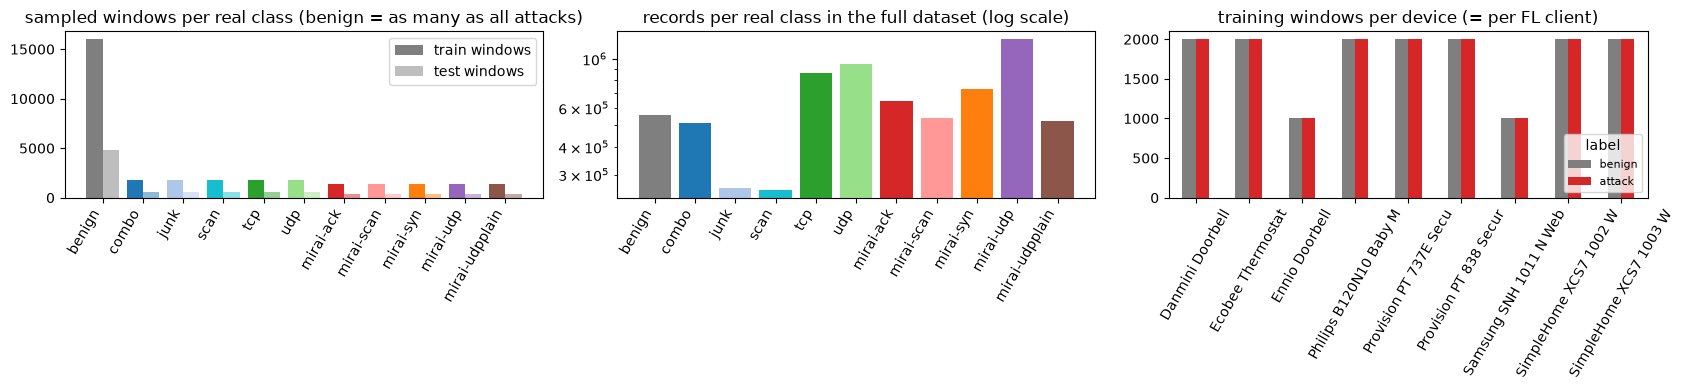

In [7]:
ORDER = ["benign", "combo", "junk", "scan", "tcp", "udp", "mirai-ack", "mirai-scan", "mirai-syn", "mirai-udp", "mirai-udpplain"]
cmap = {a: c for a, c in zip(ORDER, ["#7f7f7f", "#1f77b4", "#aec7e8", "#17becf", "#2ca02c", "#98df8a", "#d62728", "#ff9896", "#ff7f0e", "#9467bd", "#8c564b"])}
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
c_tr = M_TR.attack.value_counts().reindex(ORDER); c_te = M_TE.attack.value_counts().reindex(ORDER)
x = np.arange(len(ORDER)); ax[0].bar(x - 0.2, c_tr.values, 0.4, color=[cmap[a] for a in ORDER], label="train windows"); ax[0].bar(x + 0.2, c_te.values, 0.4, color=[cmap[a] for a in ORDER], alpha=0.5, label="test windows")
ax[0].set_xticks(x); ax[0].set_xticklabels(ORDER, rotation=60, ha="right"); ax[0].set_title("sampled windows per real class (benign = as many as all attacks)"); ax[0].legend()
rc = ROWS.groupby("attack").rows.sum().reindex(ORDER); ax[1].bar(x, rc.values, color=[cmap[a] for a in ORDER]); ax[1].set_yscale("log")
ax[1].set_xticks(x); ax[1].set_xticklabels(ORDER, rotation=60, ha="right"); ax[1].set_title("records per real class in the full dataset (log scale)")
dv = M_TR.groupby(["device", "y"]).size().unstack(fill_value=0); dv.index = [d.replace("_", " ")[:22] for d in dv.index]
dv.rename(columns={0: "benign", 1: "attack"}).plot.bar(ax=ax[2], color=["#7f7f7f", "#d62728"]); ax[2].legend(title="label", loc="lower right", fontsize=8); ax[2].set_title("training windows per device (= per FL client)"); ax[2].tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.show()

**2-D views of the real observations.** Each point below is one real traffic record (the last record of a training window), coloured by its ground-truth class; 6,000 random points are drawn. First the raw coordinates of the first two PCA components (fitted on the training region), then the same two coordinates after the rescaling to [0, pi], i.e. the first two rotation angles that enter the circuit. Benign traffic (grey) is clearly separated from most attack families, while several families overlap in these two components.

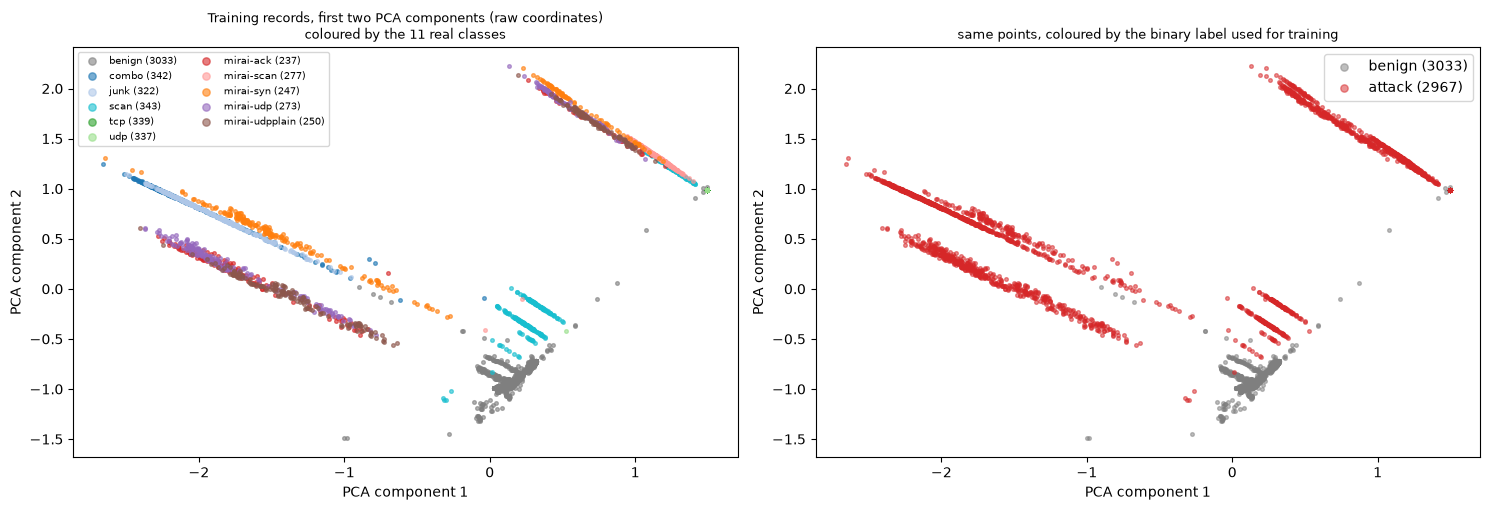

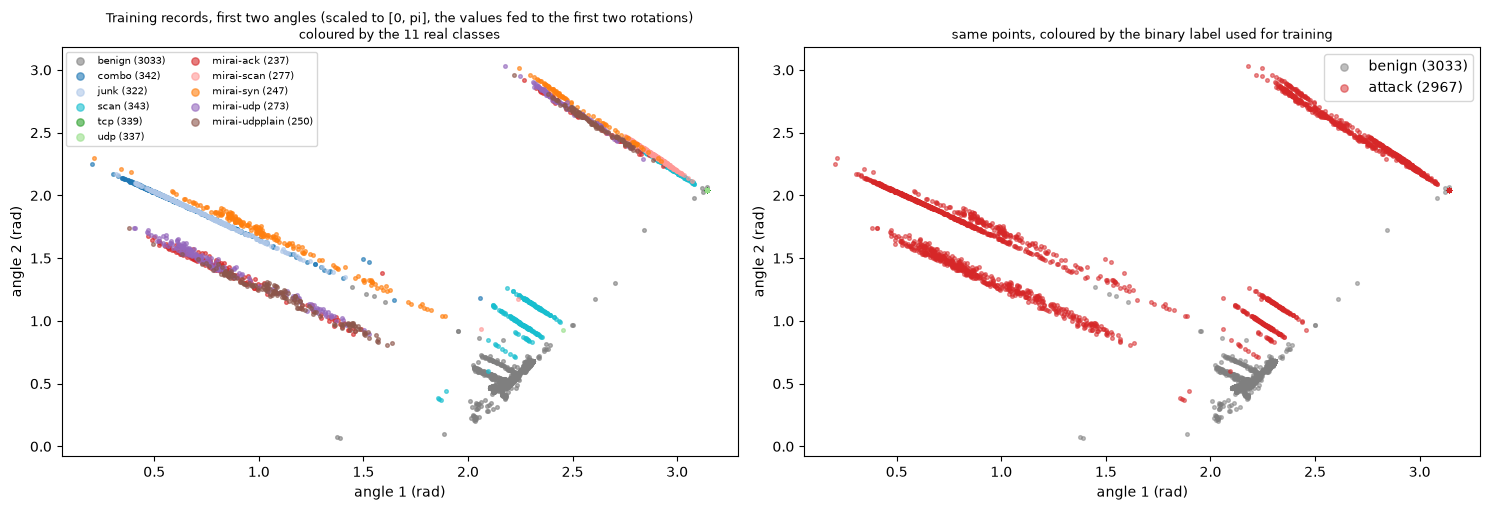

In [8]:
rng_plot = np.random.default_rng(SEED); sel = rng_plot.choice(len(P_TR), size=min(6000, len(P_TR)), replace=False)
last_raw, last_ang, lab_sel = P_TR[sel, -1], A_TR[sel, -1], M_TR.attack.values[sel]
for title, Z, xl, yl in (("Training records, first two PCA components (raw coordinates)", last_raw, "PCA component 1", "PCA component 2"),
                         ("Training records, first two angles (scaled to [0, pi], the values fed to the first two rotations)", last_ang, "angle 1 (rad)", "angle 2 (rad)")):
    fig, ax = plt.subplots(1, 2, figsize=(15, 5.2))
    for a in ORDER:
        m = lab_sel == a
        ax[0].scatter(Z[m, 0], Z[m, 1], s=7, alpha=0.6, color=cmap[a], label=f"{a} ({m.sum()})")
    ax[0].set_title(title + "\ncoloured by the 11 real classes", fontsize=9); ax[0].set_xlabel(xl); ax[0].set_ylabel(yl); ax[0].legend(fontsize=7, markerscale=2, ncol=2)
    for yv, col, nm in ((0, "#7f7f7f", "benign"), (1, "#d62728", "attack")):
        m = (Y_TR[sel] == yv); ax[1].scatter(Z[m, 0], Z[m, 1], s=7, alpha=0.5, color=col, label=f"{nm} ({m.sum()})")
    ax[1].set_title("same points, coloured by the binary label used for training", fontsize=9); ax[1].set_xlabel(xl); ax[1].set_ylabel(yl); ax[1].legend(markerscale=2)
    plt.tight_layout(); plt.show()

## Quantum Circuit Architecture

The paper's Figure 3 shows the QRNN as repeated blocks of "ansatz" acting on a hidden register H and a data register D that receives the input of the current time step, followed by measurements. The text does not give the gates (Table 1 only says "BitFlip + QuantumNeuron + Unitary"), so the circuit below is our reading of the figure (every item is marked `# CHOICE:`):

* **8 qubits.** Wires 0 to 3 are the hidden register H, wires 4 to 7 the data register D.
* **Data encoding at every time step t.** The eight angles of the window's record t are written onto the four D qubits: `RY(x[t, j])` then `RZ(x[t, j+4])` on D qubit j (two angles per qubit).
* **Ansatz (the "unitary"), shared by all time steps.** `L_LAYERS = 2` layers of trainable `RY(theta)`, `RZ(phi)` on all eight wires, followed by a ring of CNOTs `0->1, 1->2, ..., 7->0` that couples H and D. Because the same weights are used at every step and the state carries the memory from step to step, the block is recurrent.
* **Measurement.** After the last time step the Pauli-Z expectation of all eight qubits is read out. A classical head `Linear(8,16) - tanh - dropout(0.2) - Linear(16,2)` turns them into the two class scores (Table 1: hidden size 16, tanh, dropout 0.2, output 2).
* We do not reset D between steps (a reset needs mid-circuit measurement and a density-matrix simulation; the paper does not define it) and we have no explicit "BitFlip" gate.

`qrnn_qnode` is the PennyLane circuit (the reference and what is drawn). Training thousands of batches through PennyLane's `default.qubit` costs about a second per step on a CPU, so `qrnn_twin` computes the *same* circuit as one batched PyTorch state-vector calculation; the cell after the drawing proves that both agree on values and gradients to about 1e-15.

In [9]:
NQ, ND = N_QUBITS, N_DATA_Q

def qrnn_qnode(T, L):
    """The circuit that is executed: T time steps of [data encoding on D, L trainable layers + CNOT ring on all wires], readout <Z> on 8 wires."""
    dev = qml.device("default.qubit", wires=NQ)
    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def qrnn(x, w):                                           # x: (..., T, 8) angles, w: (L, 8, 2) trainable angles
        for t in range(T):
            for j in range(ND):                               # CHOICE: two angles per data qubit
                qml.RY(x[..., t, j], wires=ND + j); qml.RZ(x[..., t, ND + j], wires=ND + j)
            for l in range(L):                                # CHOICE: ansatz = RY, RZ on every wire + CNOT ring
                for q in range(NQ):
                    qml.RY(w[l, q, 0], wires=q); qml.RZ(w[l, q, 1], wires=q)
                for q in range(NQ):
                    qml.CNOT(wires=[q, (q + 1) % NQ])
        return [qml.expval(qml.PauliZ(q)) for q in range(NQ)]
    return qrnn

# ---- batched PyTorch twin (identical maths, ~10x faster than default.qubit) ----
_idx = np.arange(2 ** NQ); _bits = (_idx[:, None] >> (NQ - 1 - np.arange(NQ))[None, :]) & 1       # wire 0 = most significant bit
ZSIGN = torch.tensor(1.0 - 2.0 * _bits, dtype=torch.float64)
def _ring_inverse_permutation():
    f = _idx.copy()
    for q in range(NQ):                                       # CNOT(q -> q+1) in order, acting on basis labels
        c, t = q, (q + 1) % NQ; f = f ^ (((f >> (NQ - 1 - c)) & 1) << (NQ - 1 - t))
    inv = np.empty_like(f); inv[f] = _idx
    return torch.tensor(inv, dtype=torch.long)
RING_INV = _ring_inverse_permutation()

def _rot(ay, az):
    """RZ(az) RY(ay) as a 2x2 complex matrix for every element of the (broadcast) angle tensors"""
    c, s = torch.cos(ay / 2).to(torch.complex128), torch.sin(ay / 2).to(torch.complex128)
    e, f = torch.exp(-0.5j * az.to(torch.complex128)), torch.exp(0.5j * az.to(torch.complex128))
    return torch.stack([torch.stack([e * c, -e * s], -1), torch.stack([f * s, f * c], -1)], -2)
def _kron4(M):
    """M (..., 4, 2, 2) -> Kronecker product of the four single-qubit gates, (..., 16, 16); the first gate is the most significant qubit"""
    return torch.einsum('...ab,...cd,...ef,...gh->...acegbdfh', M[..., 0, :, :], M[..., 1, :, :], M[..., 2, :, :], M[..., 3, :, :]).reshape(*M.shape[:-3], 16, 16)

def qrnn_twin_pop(x, W):
    """x (B,T,8) angles, W (P,L,8,2) circuit angles of P independent parameter sets -> (P,B,8) expectation values <Z_q>.
    The same circuit as qrnn_qnode, evaluated for a whole mini-batch and a whole population at once."""
    B, T, _ = x.shape; P, L = W.shape[:2]; nh = 2 ** ND
    R = _rot(W[..., 0], W[..., 1])                                         # (P,L,8,2,2) trainable rotations RZ(phi) RY(theta)
    KH, KD = _kron4(R[:, :, :ND]), _kron4(R[:, :, ND:])                    # (P,L,16,16): register H = wires 0-3, register D = wires 4-7
    E = _kron4(_rot(x[:, :, :ND], x[:, :, ND:]))                           # (B,T,16,16): data encoding on the D register
    psi = torch.zeros(P, B, 2 ** NQ, dtype=torch.complex128); psi[..., 0] = 1
    for t in range(T):
        psi = torch.einsum('pbhd,bed->pbhe', psi.reshape(P, B, nh, nh), E[:, t])
        for l in range(L):
            psi = torch.einsum('pij,pbjk,plk->pbil', KH[:, l], psi, KD[:, l]).reshape(P, B, -1)[..., RING_INV]   # rotations, then the CNOT ring
            psi = psi.reshape(P, B, nh, nh)
    psi = psi.reshape(P, B, -1)
    return (psi.real ** 2 + psi.imag ** 2) @ ZSIGN
def qrnn_twin(x, w): return qrnn_twin_pop(x, w[None])[0]                  # (B,T,8), (L,8,2) -> (B,8)print("circuit and twin defined: qubits", NQ, "| data register wires", list(range(ND, NQ)), "| hidden register wires", list(range(ND)))

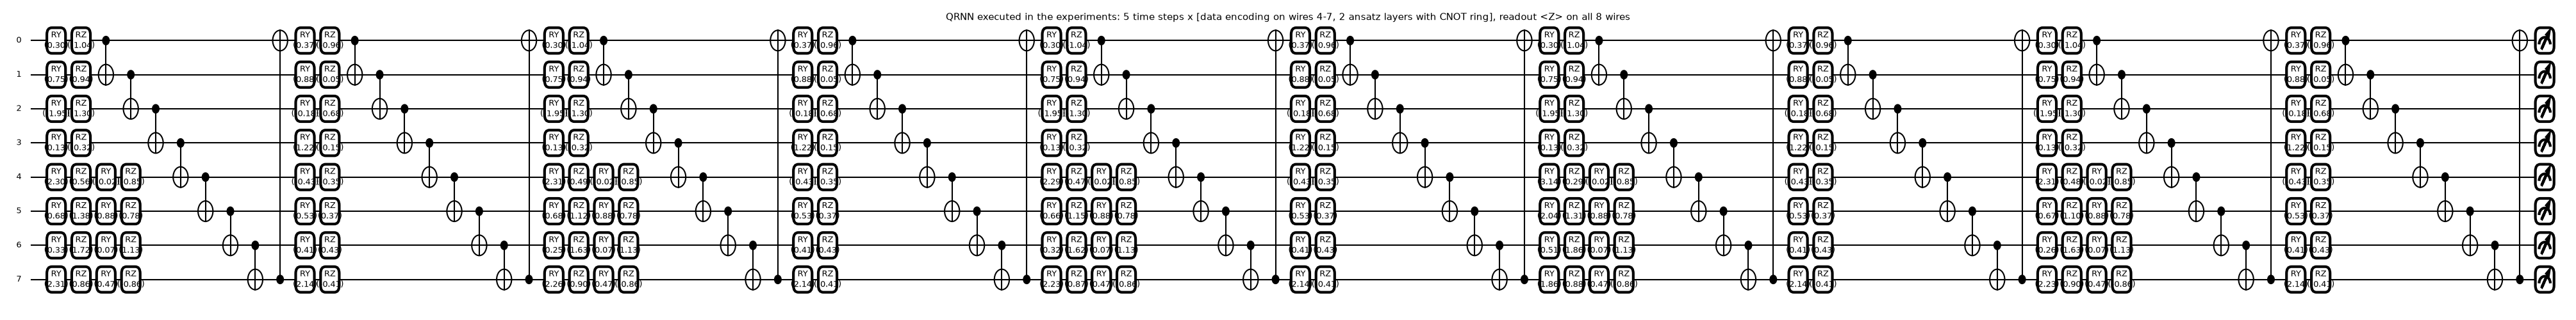

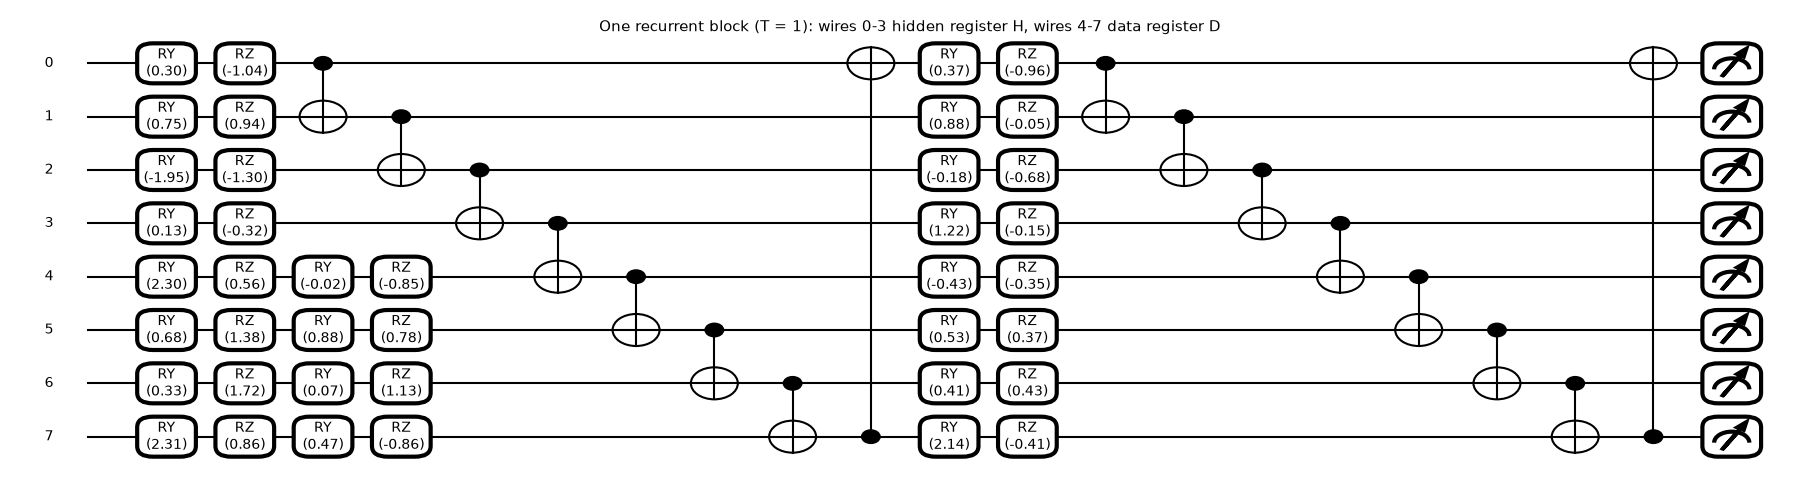

Qubits                    : 8 (H = wires 0-3, D = wires 4-7)
Circuit depth (T = 5)     : 100 | gates: {'RY': 100, 'RZ': 100, 'CNOT': 80}
Trainable quantum params  : 32 = 2 layers x 8 qubits x 2 angles (shared by all time steps)
Classical head params     : 178 -> QRNN model total: 210



  T  layers  max |value diff|  max |gradient diff|
 1       1      6.383782e-16         1.776357e-15
 3       2      3.885781e-16         3.552714e-15
 5       2      5.828671e-16         2.997602e-15
twin == PennyLane circuit (values and gradients agree to better than 1e-10)


In [10]:
# ---- the circuit actually executed: PennyLane drawing of a real training window (T = T_MAIN steps, L = L_LAYERS) ----
qn = qrnn_qnode(T_MAIN, L_LAYERS)
x_demo = torch.tensor(A_TR[0, :T_MAIN], dtype=torch.float64)                       # a real encoded training window, shape (T, 8)
w_demo = torch.tensor(np.random.default_rng(SEED).normal(0, 1, (L_LAYERS, NQ, 2)), dtype=torch.float64)
fig, ax = qml.draw_mpl(qn, decimals=2, fontsize=9)(x_demo, w_demo)
fig.set_size_inches(min(60, 3.2 * T_MAIN * L_LAYERS + 8), 4.8); fig.suptitle(f"QRNN executed in the experiments: {T_MAIN} time steps x [data encoding on wires 4-7, {L_LAYERS} ansatz layers with CNOT ring], readout <Z> on all 8 wires", fontsize=11); plt.show()

# ... and the single recurrent block that is repeated T times (same function, T = 1)
qn1 = qrnn_qnode(1, L_LAYERS); fig, ax = qml.draw_mpl(qn1, decimals=2, fontsize=10)(x_demo[:1], w_demo)
fig.set_size_inches(18, 4.8); fig.suptitle("One recurrent block (T = 1): wires 0-3 hidden register H, wires 4-7 data register D", fontsize=11); plt.show()

res = qml.specs(qn)(x_demo, w_demo)["resources"]
print("Qubits                    :", NQ, f"(H = wires 0-3, D = wires 4-7)")
print("Circuit depth (T = %d)     :" % T_MAIN, res.depth, "| gates:", dict(res.gate_types))
print("Trainable quantum params  :", w_demo.numel(), f"= {L_LAYERS} layers x {NQ} qubits x 2 angles (shared by all time steps)")
head_params = (NQ * HIDDEN + HIDDEN) + (HIDDEN * 2 + 2)
print("Classical head params     :", head_params, "-> QRNN model total:", w_demo.numel() + head_params)

# ---- equivalence: PennyLane circuit vs batched twin (values and gradients), float64 ----
rows = []
for T_, L_ in ((1, 1), (3, 2), (T_MAIN, L_LAYERS)):
    q_ = qrnn_qnode(T_, L_); xb = torch.rand(6, T_, NQ, dtype=torch.float64) * np.pi; wb = (torch.rand(L_, NQ, 2, dtype=torch.float64) * 2 * np.pi).requires_grad_()
    ref = torch.stack(q_(xb, wb), -1); tw = qrnn_twin(xb, wb)
    wp =(torch.rand(3, L_, NQ, 2, dtype=torch.float64) * 2 * np.pi); wp[1] = wb.detach(); tp = qrnn_twin_pop(xb, wp)[1]      # population version, member 1 = wb
    g1 = torch.autograd.grad(ref.sum(), wb)[0]; g2 = torch.autograd.grad(tw.sum(), wb)[0]
    rows.append({"T": T_, "layers": L_, "max |value diff|": float(max((ref - tw).abs().max(), (ref - tp).abs().max()).detach()), "max |gradient diff|": float((g1 - g2).abs().max())})
EQ = pd.DataFrame(rows); print("\n", EQ.to_string(index=False))
assert EQ["max |value diff|"].max() < 1e-10 and EQ["max |gradient diff|"].max() < 1e-10, "twin differs from the PennyLane circuit"
print("twin == PennyLane circuit (values and gradients agree to better than 1e-10)")

## 4. The models, the DWMA optimiser and the federated loop

**The two networks.** `QRNNClassifier` is the paper's model as we read it: the 8-qubit circuit above produces eight expectation values, a small classical head (hidden size 16, tanh, dropout 0.2, two outputs) turns them into class scores. `LSTMClassifier` is the classical recurrent baseline of the paper (its reference [31]): an LSTM with hidden size 16 reading the same windows of eight numbers, followed by the same kind of head. Both see exactly the same inputs.

**Federated learning.** One client per IoT device. In every round each client starts from the current global parameters, trains on its own windows only (the raw traffic never leaves the client), and the server replaces the global parameters with the **plain average** of the nine clients' parameters (the paper's "average method", i.e. FedAvg with equal weights). Clients are stateless: their optimiser is re-created every round.

**The DWMA optimiser** (paper section 4.1.2.3.2) is a gradient-free, population-based search over the circuit parameters. A *doll* is one candidate parameter vector; its fitness is the mean squared error of eq. (7) between the target and the predicted attack probability on the current mini-batch. One iteration has two phases:

1. *Exploration* ("pattern selection and sewing", eq. 9): `Z_new = Z + d * (E - W * Z)` where `E` is a randomly chosen other doll (the "pattern"), `d` is uniform in [0, 1] for every coordinate and `W` is 1 or 2.
2. *Exploitation* ("beautifying the details", eq. 17): `Z_new = Z + (1 - 2d) * gamma * (upper - lower) / (1 + e)`, small steps that shrink with the iteration counter `e`.

In each phase the candidate is blended with the doll's exponentially weighted moving average (EWMA, eqs. 13 to 15): `Z_cand = beta * Z_new + (1 - beta) * ZE` and `ZE <- beta * Z + (1 - beta) * ZE` (our reading of the garbled eq. 15), and it replaces the doll only if its fitness is not worse (eqs. 16 and 18). All dolls of a phase are generated from the population as it was at the start of the phase and evaluated together (a synchronous variant, much cheaper to simulate than doll-by-doll updates). Setting `beta = 1` gives plain **DOA**; replacing the dollmaker moves by Gaussian proposals gives an **EWMA-only** search; these two are the ablations of the paper's Figures 8 and 9. The classical head is trained with Adam on the quantum read-outs of the best doll. All of the DWMA constants are `# CHOICE:` items because the paper gives none.

**How the three step constants were chosen (no test data involved).** Taken literally, eq. (9) with a unit step lets a doll jump across the whole angle range, and nine clients that each jump somewhere else cannot be averaged. We therefore added a step factor `DWMA_ETA` to eq. (9), a spread `DWMA_SIGMA` for the starting population and a factor `DWMA_GAMMA` for eq. (17), and tried four settings in a separate federated run (seed 7, same budget as FAST_MODE) scored on 3,000 *training-region* windows that no client had used for training:

| sigma | eta | gamma | validation accuracy | validation loss |
|---|---|---|---|---|
| 0.3 | 1.0 (literal eq. 9) | 0.1 | 0.846 | 0.555 |
| 0.1 | 0.3 | 0.05 | 0.960 | 0.140 |
| **0.05** | **0.2** | **0.03** | **0.972** | **0.136** |
| 0.1 | 0.5 | 0.05 | 0.947 | 0.198 |

The third row is used everywhere below. At that setting the validation accuracy was 0.960 for DOA alone and 0.984 for the EWMA-only search (the ablations were run once, at this setting only). The test windows played no role in this choice.

In [11]:
import copy

class QRNNClassifier(nn.Module):
    def __init__(self, seed):
        super().__init__()
        g = torch.Generator().manual_seed(int(seed))
        self.w = nn.Parameter(torch.randn(L_LAYERS, NQ, 2, generator=g, dtype=torch.float64))        # circuit angles (CHOICE: N(0,1) start)
        self.head = nn.Sequential(nn.Linear(NQ, HIDDEN), nn.Tanh(), nn.Dropout(DROPOUT), nn.Linear(HIDDEN, 2))   # Table 1: hidden 16, tanh, dropout 0.2, output 2
    def quantum(self, x): return qrnn_twin(x.double(), self.w).float()
    def forward(self, x): return self.head(self.quantum(x))

class LSTMClassifier(nn.Module):
    def __init__(self, seed):
        super().__init__(); torch.manual_seed(int(seed))
        self.rnn = nn.LSTM(NQ, HIDDEN, batch_first=True); self.drop = nn.Dropout(DROPOUT); self.fc = nn.Linear(HIDDEN, 2)
    def forward(self, x): return self.fc(self.drop(self.rnn(x)[0][:, -1]))

def n_params(m): return sum(p.numel() for p in m.parameters())
print("trainable parameters: QRNN", n_params(QRNNClassifier(0)), "(32 quantum +", n_params(QRNNClassifier(0)) - 32, "classical) | LSTM", n_params(LSTMClassifier(0)))


class DWMA:
    """Dollmaker weighted moving average optimiser (population search). mode: 'dwma' (DOA + EWMA), 'doa' (beta = 1), 'ewma' (random proposals + EWMA)."""
    def __init__(self, x0, pop, rng, mode="dwma", beta=None, sigma=None, gamma=None, eta=None, lb=-np.pi, ub=np.pi):
        self.rng, self.mode, self.pop, self.dim = rng, mode, pop, len(x0)
        beta = BETA if beta is None else beta; sigma = DWMA_SIGMA if sigma is None else sigma; gamma = DWMA_GAMMA if gamma is None else gamma; self.eta = DWMA_ETA if eta is None else eta
        self.beta = 1.0 if mode == "doa" else beta                      # CHOICE: beta = 0.7; DOA = no smoothing
        self.sigma, self.gamma, self.lb, self.ub, self.e = sigma, gamma, lb, ub, 0   # CHOICE: sigma, gamma, bounds [-pi, pi]
        self.Z = x0[None] + sigma * rng.standard_normal((pop, self.dim)); self.Z[0] = x0     # doll 0 = current solution
        self.ZE = self.Z.copy(); self.fit = np.full(pop, np.inf)
    def _accept(self, cand, f):
        """EWMA blend of every candidate (eqs. 13-15), evaluation of the whole population at once, greedy replacement (eqs. 16, 18)"""
        cand = np.clip(self.beta * cand + (1 - self.beta) * self.ZE, self.lb, self.ub)
        fc = f(cand); better = fc <= self.fit
        self.Z[better], self.fit[better] = cand[better], fc[better]
        self.ZE = self.beta * self.Z + (1 - self.beta) * self.ZE
    def step(self, f):
        """f maps a (pop, dim) array of candidate vectors to a (pop,) array of fitness values. Dolls are updated synchronously (CHOICE)."""
        self.e += 1; r = self.rng; P = self.pop
        self.fit = f(self.Z)                                           # the mini-batch changes every step: re-evaluate the population
        if self.mode == "ewma": cand = self.Z + self.sigma * r.standard_normal((P, self.dim))
        else:                                                          # phase 1: exploration, eq. (9): move towards a random other doll (the pattern E)
            k = (np.arange(P) + 1 + r.integers(P - 1, size=P)) % P; W = r.integers(1, 3, size=(P, 1))
            cand = self.Z + self.eta * r.random((P, self.dim)) * (self.Z[k] - W * self.Z)
        self._accept(cand, f)
        cand = self.Z + (1 - 2 * r.random((P, self.dim))) * self.gamma * (self.ub - self.lb) / (1 + self.e)     # phase 2: exploitation, eq. (17)
        self._accept(cand, f)
        b = int(np.argmin(self.fit)); return self.Z[b].copy(), float(self.fit[b])

def make_clients(T, frac, rng, A=None, Y=None, M=None):
    """One client per device: its training windows from the first `frac` of every file, the last T records of each window."""
    A, Y, M = (A_TR if A is None else A), (Y_TR if Y is None else Y), (M_TR if M is None else M)
    ok = ((M.start.values + T_MAX) / M.n_rows.values) <= frac + 1e-9
    clients = {}
    for dev in sorted(M.device.unique()):
        idx = np.where(ok & (M.device.values == dev))[0]
        if len(idx) > CLIENT_CAP: idx = rng.choice(idx, CLIENT_CAP, replace=False)
        clients[dev] = (torch.tensor(A[idx, T_MAX - T:]), torch.tensor(Y[idx]))
    return clients

@torch.no_grad()
def predict_proba(model, A, bs=512):
    model.eval(); out = []
    for i in range(0, len(A), bs): out.append(torch.softmax(model(A[i:i + bs]), -1)[:, 1])
    return torch.cat(out).numpy()

def metrics(y, p):
    yhat = (p >= 0.5).astype(int); pr, rc, f1, _ = precision_recall_fscore_support(y, yhat, average="binary", zero_division=0)
    return dict(acc=accuracy_score(y, yhat), precision=pr, recall=rc, f1=f1, mse=float(np.mean((p - y) ** 2)),
                loss=float(-np.mean(np.log(np.clip(np.where(y == 1, p, 1 - p), 1e-7, 1)))), cm=confusion_matrix(y, yhat, labels=[0, 1]))

def local_train(model, X, y, steps, opt_name, pop, rng):
    n = len(X)
    if opt_name == "adam":
        opt = torch.optim.Adam(model.parameters(), lr=LR); model.train()
        for _ in range(steps):
            idx = torch.tensor(rng.choice(n, BATCH, replace=False)); loss = F.cross_entropy(model(X[idx]), y[idx])
            opt.zero_grad(); loss.backward(); opt.step()
        return float(loss)
    # DWMA / DOA / EWMA: population search over the circuit angles, Adam for the classical head
    head_opt = torch.optim.Adam(model.head.parameters(), lr=LR); shape = tuple(model.w.shape)
    dw = DWMA(model.w.detach().numpy().ravel().copy(), pop, rng, mode=opt_name); best_fit = np.nan
    for _ in range(steps):
        idx = torch.tensor(rng.choice(n, BATCH, replace=False)); xb, yb = X[idx], y[idx].float()
        def fitness(Z):                                                    # eq. (7): mean squared error between target and network output, one value per doll
            with torch.no_grad():
                model.head.eval(); q = qrnn_twin_pop(xb.double(), torch.tensor(Z.reshape((len(Z),) + shape))).float()      # (pop, B, 8)
                p = torch.softmax(model.head(q), -1)[..., 1]
            return ((p - yb[None]) ** 2).mean(1).numpy().astype(np.float64)
        z, best_fit = dw.step(fitness); model.w.data = torch.tensor(z.reshape(shape))
        model.head.train()
        with torch.no_grad(): feats = model.quantum(xb)
        loss = F.cross_entropy(model.head(feats), y[idx]); head_opt.zero_grad(); loss.backward(); head_opt.step()
    return best_fit

def average_states(states):
    return {k: torch.stack([s[k] for s in states]).mean(0) for k in states[0]}

def run_fl(kind, opt_name, seed, T=None, frac=0.9, rounds=None, steps=None, pop=None, eval_every=True):
    """Federated training. kind: 'qrnn' | 'lstm'; opt_name: 'adam' | 'dwma' | 'doa' | 'ewma'. Returns the final test metrics and the per-round history."""
    T = T or T_MAIN; rounds = rounds or ROUNDS; steps = steps or LOCAL_STEPS; pop = pop or POP
    set_seed(seed); rng = np.random.default_rng(seed); clients = make_clients(T, frac, rng)
    glob = QRNNClassifier(seed) if kind == "qrnn" else LSTMClassifier(seed)
    A_te = torch.tensor(A_TE[:, T_MAX - T:]); sub = np.random.default_rng(SEED).choice(len(A_te), min(EVAL_CAP, len(A_te)), replace=False)
    hist = []; t0 = time.time()
    for r in range(rounds):
        states, fits = [], []
        for dev, (X, y) in clients.items():
            m = copy.deepcopy(glob); fits.append(local_train(m, X, y, steps, opt_name, pop, rng)); states.append(m.state_dict())
        glob.load_state_dict(average_states(states))
        if eval_every:
            mt = metrics(Y_TE[sub], predict_proba(glob, A_te[sub])); hist.append(dict(round=r + 1, acc=mt["acc"], loss=mt["loss"], mse=mt["mse"], local_fitness=float(np.nanmean(fits)), sec=time.time() - t0))
    final = metrics(Y_TE, predict_proba(glob, A_te)); final["seconds"] = time.time() - t0; final["params"] = n_params(glob)
    return final, pd.DataFrame(hist), glob

# smoke test: one tiny federated run to check that the loop works and to time it
t0 = time.time(); r_, h_, _ = run_fl("qrnn", "adam", SEED, rounds=1, steps=2)
print(f"smoke test (1 round, 2 local steps): test accuracy {r_['acc']:.3f}, {time.time()-t0:.1f} s")

trainable parameters: QRNN 210 (32 quantum + 178 classical) | LSTM 1698


smoke test (1 round, 2 local steps): test accuracy 0.902, 24.7 s


## 5. Main experiment: federated QRNN with Adam, federated DWMA_QRNN, federated LSTM, random forest, SVM

Nine clients (one per device), `ROUNDS` federated rounds of `LOCAL_STEPS` local steps, windows of `T_MAIN` records, 90 % of every traffic file for training and the last 10 % for testing, the same balanced test windows for every model. Besides the two federated QRNNs and the federated LSTM we train two classical models on the *pooled* training windows (flattened to `T_MAIN x 8` numbers): a random forest and an RBF-kernel SVM (on a random subset of 6,000 windows so that it finishes in seconds). No hyper-parameter was tuned on the test data; the test set is used once per model for the final numbers (the per-round curves use a fixed random subset of the test windows for display only, and nothing is selected from them).

In [12]:
CONFIGS = [("QRNN, Adam (federated)", "qrnn", "adam"), ("DWMA_QRNN (federated)", "qrnn", "dwma"), ("LSTM (federated)", "lstm", "adam")]
RUNS = {}                                    # (model name, seed) -> (final metrics, per-round history)
t_all = time.time()
for seed in SEEDS:
    for name, kind, opt in CONFIGS:
        if opt != "adam" and seed not in DW_SEEDS: continue           # population optimisers: fewer seeds in FAST_MODE
        fin, hist, _ = run_fl(kind, opt, seed); RUNS[(name, seed)] = (fin, hist)
        print(f"seed {seed} | {name:24s} acc {fin['acc']:.4f}  F1 {fin['f1']:.4f}  loss {fin['loss']:.4f}  mse {fin['mse']:.4f}  ({fin['seconds']:.0f} s)", flush=True)

# classical models on the pooled windows (same angles, flattened)
Xf_tr = A_TR[:, T_MAX - T_MAIN:].reshape(len(A_TR), -1); Xf_te = A_TE[:, T_MAX - T_MAIN:].reshape(len(A_TE), -1)
for seed in SEEDS:
    t0 = time.time(); rf = RandomForestClassifier(n_estimators=100, random_state=seed, n_jobs=1).fit(Xf_tr, Y_TR)
    fin = metrics(Y_TE, rf.predict_proba(Xf_te)[:, 1]); fin["seconds"] = time.time() - t0; fin["params"] = np.nan; RUNS[("Random forest (pooled)", seed)] = (fin, pd.DataFrame())
    sub = np.random.default_rng(seed).choice(len(Xf_tr), 6000, replace=False); t0 = time.time()
    sv = SVC(kernel="rbf", probability=True, random_state=seed).fit(Xf_tr[sub], Y_TR[sub])
    fin = metrics(Y_TE, sv.predict_proba(Xf_te)[:, 1]); fin["seconds"] = time.time() - t0; fin["params"] = np.nan; RUNS[("SVC rbf (pooled)", seed)] = (fin, pd.DataFrame())
NAMES = [c[0] for c in CONFIGS] + ["Random forest (pooled)", "SVC rbf (pooled)"]
print(f"\nall main runs finished in {(time.time()-t_all)/60:.1f} min")

rows = []
for n in NAMES:
    R = [RUNS[(n, s)][0] for s in SEEDS if (n, s) in RUNS]
    row = {"model": n, "seeds": len(R)}
    for k in ("acc", "precision", "recall", "f1", "loss", "mse", "seconds"):
        v = np.array([r[k] for r in R]); row[k] = f"{v.mean():.4f} +- {v.std():.4f}" if k != "seconds" else f"{v.mean():.0f}"
    row["parameters"] = R[0]["params"]; rows.append(row)
MAIN = pd.DataFrame(rows); print(f"\nFinal test metrics, mean +- std over seeds {SEEDS} (balanced test set, {len(Y_TE)} windows):"); print(MAIN.to_string(index=False))

seed 42 | QRNN, Adam (federated)   acc 0.9553  F1 0.9571  loss 0.1590  mse 0.0392  (43 s)


seed 42 | DWMA_QRNN (federated)    acc 0.9235  F1 0.9266  loss 0.3279  mse 0.0866  (119 s)


seed 42 | LSTM (federated)         acc 0.9205  F1 0.9141  loss 0.2002  mse 0.0612  (1 s)


seed 43 | QRNN, Adam (federated)   acc 0.9804  F1 0.9808  loss 0.1010  mse 0.0216  (18 s)


seed 43 | LSTM (federated)         acc 0.9444  F1 0.9412  loss 0.1559  mse 0.0440  (1 s)



all main runs finished in 3.9 min

Final test metrics, mean +- std over seeds [42, 43] (balanced test set, 9600 windows):
                 model  seeds              acc        precision           recall               f1             loss              mse seconds  parameters
QRNN, Adam (federated)      2 0.9679 +- 0.0126 0.9423 +- 0.0215 0.9973 +- 0.0010 0.9689 +- 0.0118 0.1300 +- 0.0290 0.0304 +- 0.0088      31       210.0
 DWMA_QRNN (federated)      1 0.9235 +- 0.0000 0.8910 +- 0.0000 0.9652 +- 0.0000 0.9266 +- 0.0000 0.3279 +- 0.0000 0.0866 +- 0.0000     119       210.0
      LSTM (federated)      2 0.9324 +- 0.0119 0.9962 +- 0.0024 0.8681 +- 0.0219 0.9277 +- 0.0135 0.1780 +- 0.0221 0.0526 +- 0.0086       1      1698.0
Random forest (pooled)      2 0.9989 +- 0.0002 0.9980 +- 0.0003 0.9998 +- 0.0000 0.9989 +- 0.0002 0.0044 +- 0.0002 0.0011 +- 0.0001      24         NaN
      SVC rbf (pooled)      2 0.9974 +- 0.0001 0.9962 +- 0.0005 0.9988 +- 0.0004 0.9975 +- 0.0001 0.0074 +- 0.0008 0.

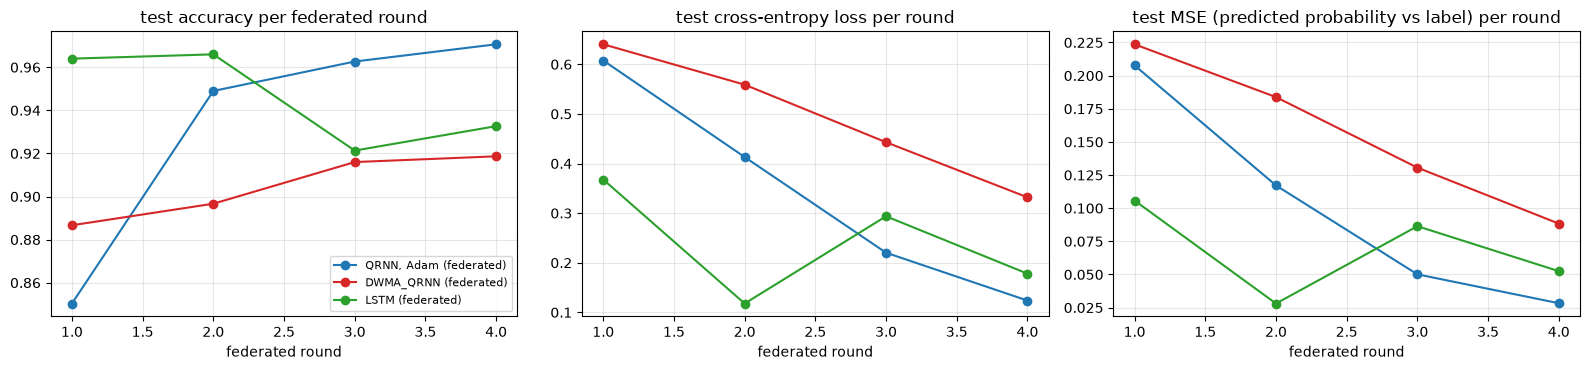

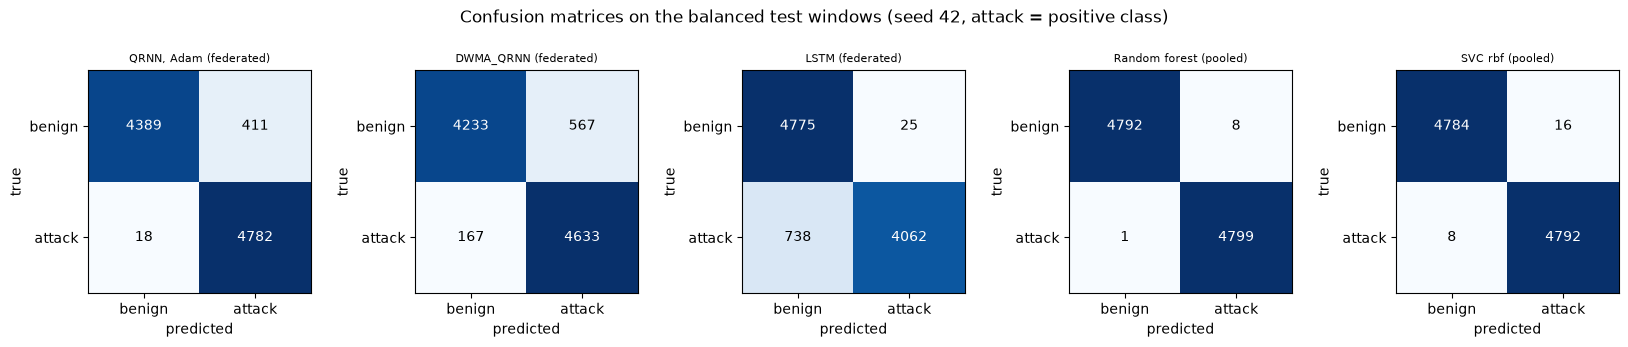

                  model  balanced accuracy  accuracy at natural mix
 QRNN, Adam (federated)             0.9679                   0.9927
  DWMA_QRNN (federated)             0.9235                   0.9586
       LSTM (federated)             0.9324                   0.8783
 Random forest (pooled)             0.9989                   0.9997
       SVC rbf (pooled)             0.9974                   0.9985
always predict 'attack'             0.5000                   0.9213


In [13]:
# ---- per-round curves (display only) and confusion matrices ----
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for (name, kind, opt), col in zip(CONFIGS, ("C0", "C3", "C2")):
    H = pd.concat([RUNS[(name, s)][1] for s in SEEDS if (name, s) in RUNS]).groupby("round").mean()
    ax[0].plot(H.index, H.acc, marker="o", color=col, label=name); ax[1].plot(H.index, H.loss, marker="o", color=col); ax[2].plot(H.index, H.mse, marker="o", color=col)
ax[0].set_title("test accuracy per federated round"); ax[1].set_title("test cross-entropy loss per round"); ax[2].set_title("test MSE (predicted probability vs label) per round")
for a in ax: a.set_xlabel("federated round"); a.grid(alpha=0.3)
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, len(NAMES), figsize=(3.3 * len(NAMES), 3.2))
for a, n in zip(ax, NAMES):
    cm = RUNS[(n, SEEDS[0])][0]["cm"]; a.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2): a.text(j, i, str(cm[i, j]), ha="center", va="center", color="w" if cm[i, j] > cm.max() / 2 else "k")
    a.set_xticks([0, 1]); a.set_xticklabels(["benign", "attack"]); a.set_yticks([0, 1]); a.set_yticklabels(["benign", "attack"]); a.set_title(n, fontsize=8); a.set_xlabel("predicted"); a.set_ylabel("true")
plt.suptitle(f"Confusion matrices on the balanced test windows (seed {SEEDS[0]}, attack = positive class)", y=1.03); plt.tight_layout(); plt.show()

# ---- what the accuracy would be on the natural class mix of N-BaIoT (92 % attack) ----
pi_att = nat_att; rows = []
for n in NAMES:
    acc_nat = []
    for s in [s for s in SEEDS if (n, s) in RUNS]:
        cm = RUNS[(n, s)][0]["cm"]; tnr, tpr = cm[0, 0] / cm[0].sum(), cm[1, 1] / cm[1].sum(); acc_nat.append(tpr * pi_att + tnr * (1 - pi_att))
    rows.append({"model": n, "balanced accuracy": np.mean([(RUNS[(n, s)][0]["cm"][0, 0] / RUNS[(n, s)][0]["cm"][0].sum() + RUNS[(n, s)][0]["cm"][1, 1] / RUNS[(n, s)][0]["cm"][1].sum()) / 2 for s in SEEDS if (n, s) in RUNS]),
                 "accuracy at natural mix": np.mean(acc_nat)})
NAT = pd.DataFrame(rows); NAT.loc[len(NAT)] = ["always predict 'attack'", 0.5, pi_att]
print(NAT.round(4).to_string(index=False))

## 6. Training-data size and number of time steps (the paper's Figures 4 to 7)

The paper varies the share of training data from 50 % to 90 % (Figures 4 and 6) and the "time step" (Figures 5 and 7). We repeat both sweeps with the federated QRNN (Adam) and the federated LSTM, one seed each (DWMA is too slow for a full sweep and is only compared in sections 5 and 8). Training data are the first `f` % of every traffic file; the test windows never change. The time-step sweep uses the last `T` records of every window; the paper's range of 20 to 100 steps is out of reach for an exact 8-qubit simulation, so we sweep `T` up to `T_MAX`.

training fraction 0.5 done


training fraction 0.9 done


time steps 2 done


time steps 5 done


time steps 10 done


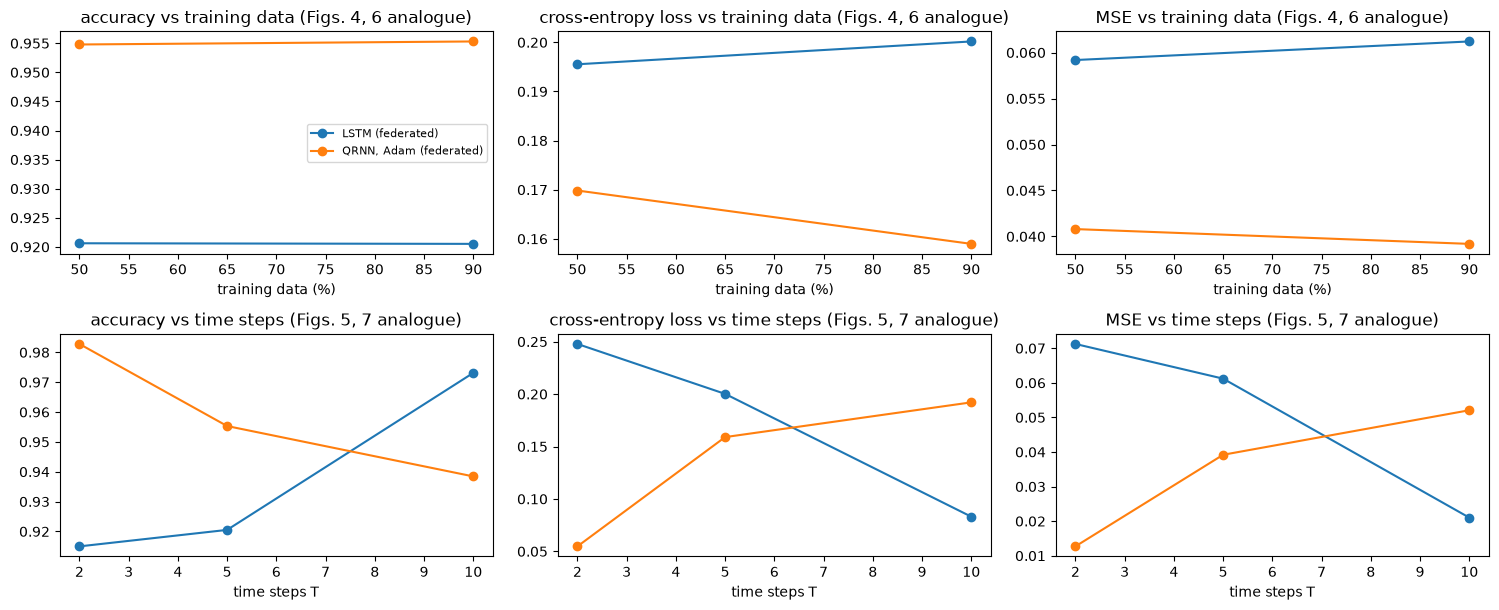

                 model  frac    acc   loss    mse
QRNN, Adam (federated)   0.5 0.9548 0.1698 0.0408
      LSTM (federated)   0.5 0.9206 0.1955 0.0592
QRNN, Adam (federated)   0.9 0.9553 0.1590 0.0392
      LSTM (federated)   0.9 0.9205 0.2002 0.0612
                 model  T    acc   loss    mse
QRNN, Adam (federated)  2 0.9828 0.0548 0.0127
      LSTM (federated)  2 0.9150 0.2478 0.0712
QRNN, Adam (federated)  5 0.9553 0.1590 0.0392
      LSTM (federated)  5 0.9205 0.2002 0.0612
QRNN, Adam (federated) 10 0.9384 0.1921 0.0521
      LSTM (federated) 10 0.9731 0.0831 0.0210


In [14]:
SW_F, SW_T = [], []
seed0 = SEEDS[0]
for f in SWEEP_FRACS:
    for name, kind, opt in (CONFIGS[0], CONFIGS[2]):
        fin, _, _ = run_fl(kind, opt, seed0, frac=f, eval_every=False); SW_F.append(dict(model=name, frac=f, acc=fin["acc"], loss=fin["loss"], mse=fin["mse"]))
    print("training fraction", f, "done", flush=True)
for T_ in SWEEP_T:
    for name, kind, opt in (CONFIGS[0], CONFIGS[2]):
        fin, _, _ = run_fl(kind, opt, seed0, T=T_, eval_every=False); SW_T.append(dict(model=name, T=T_, acc=fin["acc"], loss=fin["loss"], mse=fin["mse"]))
    print("time steps", T_, "done", flush=True)
SW_F, SW_T = pd.DataFrame(SW_F), pd.DataFrame(SW_T)
fig, ax = plt.subplots(2, 3, figsize=(15, 6.2))
for j, (m, ttl) in enumerate((("acc", "accuracy"), ("loss", "cross-entropy loss"), ("mse", "MSE"))):
    for name, g in SW_F.groupby("model"): ax[0, j].plot(100 * g.frac, g[m], marker="o", label=name)
    for name, g in SW_T.groupby("model"): ax[1, j].plot(g["T"], g[m], marker="o", label=name)
    ax[0, j].set_title(ttl + " vs training data (Figs. 4, 6 analogue)"); ax[0, j].set_xlabel("training data (%)")
    ax[1, j].set_title(ttl + " vs time steps (Figs. 5, 7 analogue)"); ax[1, j].set_xlabel("time steps T")
ax[0, 0].legend(fontsize=8); plt.tight_layout(); plt.show()
print(SW_F.round(4).to_string(index=False)); print(SW_T.round(4).to_string(index=False))

## 7. Optimisers compared (the paper's Figures 8 to 10)

Section 5.4 of the paper compares DWMA with ROA, DOA, EWMA and BOA at population sizes up to 50 (accuracy 90.161 % for DWMA against 81.9 % to 87.5 % for the others). We compare the three variants we can build from the paper's own description, **DWMA** (DOA + EWMA), **DOA** alone (`beta = 1`) and **EWMA** alone (Gaussian proposals), at the population sizes in `ALGO_POPS`, with the gradient-based Adam run as a reference. ROA and BOA are not described well enough to be re-implemented. Everything else is identical to the main experiment (one seed). The convergence panel plots the best fitness (eq. 7, the training mini-batch MSE) that the clients reach in each federated round.

population   6 | DWMA  acc 0.9235  loss 0.3279  mse 0.0866


population   6 | DOA   acc 0.9350  loss 0.2725  mse 0.0689


population   6 | EWMA  acc 0.9409  loss 0.2307  mse 0.0566


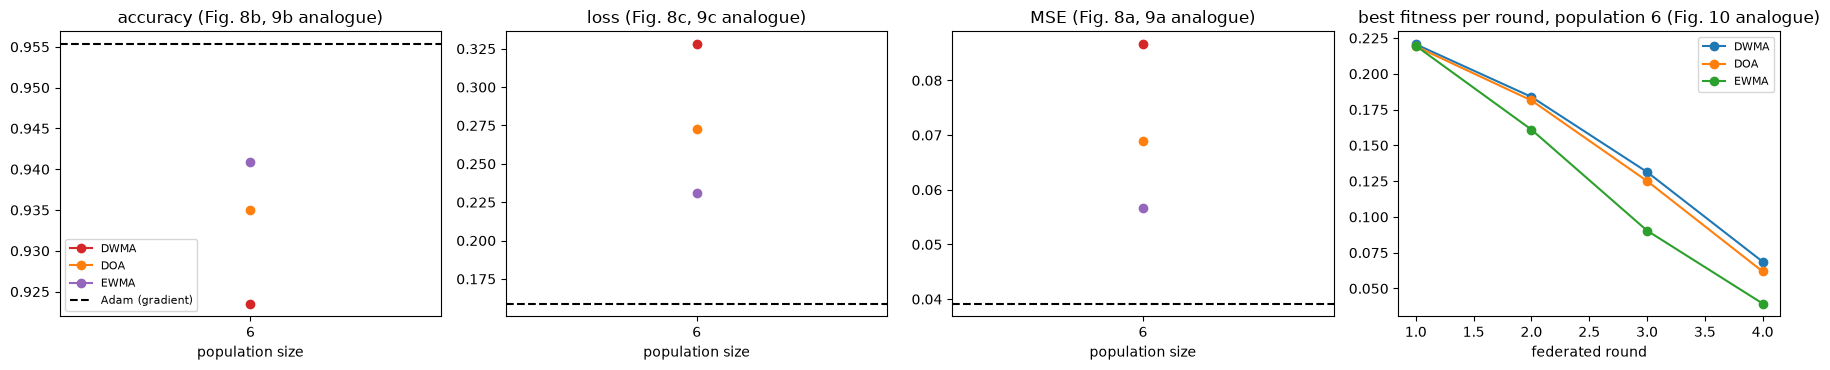

optimiser  population    acc   loss    mse  seconds
     DWMA           6 0.9235 0.3279 0.0866 119.4844
      DOA           6 0.9350 0.2725 0.0689  98.9404
     EWMA           6 0.9409 0.2307 0.0566  90.5480


In [15]:
ALG = []; CONV = {}
for pop in ALGO_POPS:
    for mode in ("dwma", "doa", "ewma"):
        if mode == "dwma" and pop == POP:
            fin, hist = RUNS[(CONFIGS[1][0], seed0)]                      # already trained in section 5 with the same seed and population
        else:
            fin, hist, _ = run_fl("qrnn", mode, seed0, pop=pop)
        ALG.append(dict(optimiser=mode.upper(), population=pop, acc=fin["acc"], loss=fin["loss"], mse=fin["mse"], seconds=fin["seconds"])); CONV[(mode, pop)] = hist
        print(f"population {pop:3d} | {mode.upper():5s} acc {fin['acc']:.4f}  loss {fin['loss']:.4f}  mse {fin['mse']:.4f}", flush=True)
fin, hist = RUNS[(CONFIGS[0][0], seed0)]; ADAM_REF = fin
ALG = pd.DataFrame(ALG)
fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
for mode, col in (("DWMA", "C3"), ("DOA", "C1"), ("EWMA", "C4")):
    g = ALG[ALG.optimiser == mode]; ax[0].plot(g.population, g.acc, marker="o", color=col, label=mode); ax[1].plot(g.population, g.loss, marker="o", color=col); ax[2].plot(g.population, g.mse, marker="o", color=col)
for a, k in zip(ax[:3], ("acc", "loss", "mse")): a.axhline(ADAM_REF[k], color="k", ls="--", label="Adam (gradient)"); a.set_xlabel("population size"); a.set_xticks(ALGO_POPS)
ax[0].set_title("accuracy (Fig. 8b, 9b analogue)"); ax[1].set_title("loss (Fig. 8c, 9c analogue)"); ax[2].set_title("MSE (Fig. 8a, 9a analogue)"); ax[0].legend(fontsize=8)
for (mode, pop), h in CONV.items():
    if pop == max(ALGO_POPS): ax[3].plot(h["round"], h.local_fitness, marker="o", label=mode.upper())
ax[3].set_title(f"best fitness per round, population {max(ALGO_POPS)} (Fig. 10 analogue)"); ax[3].set_xlabel("federated round"); ax[3].legend(fontsize=8)
plt.tight_layout(); plt.show(); print(ALG.round(4).to_string(index=False))

In [16]:
# ---- communication: what one client uploads per round (the paper's Figure 11 reports "bytes") ----
q, l = QRNNClassifier(0), LSTMClassifier(0)
comm = pd.DataFrame({"model": ["QRNN (32 circuit angles + head)", "classical LSTM"], "parameters": [n_params(q), n_params(l)],
                     "bytes per client and round (up)": [sum(p.numel() * p.element_size() for p in q.parameters()), sum(p.numel() * p.element_size() for p in l.parameters())]})
print(comm.to_string(index=False)); print(f"\nthe LSTM sends {comm.parameters[1]/comm.parameters[0]:.1f}x more parameters per round than the QRNN")

                          model  parameters  bytes per client and round (up)
QRNN (32 circuit angles + head)         210                              968
                 classical LSTM        1698                             6792

the LSTM sends 8.1x more parameters per round than the QRNN


## 8. Side by side with the paper

Every number of the paper that this notebook can test (Dataset 2, N-BaIoT) is listed with our value. The rule is the one used for all notebooks of this repository: an accuracy within 2 points (or a loss / MSE within 0.02) of the paper is **reproduced**; otherwise the verdict is **exceeded** or **not reached** with the gap (in the direction that is better for the metric); claims about quantities we cannot measure are **cannot be checked**. Our "DWMA_QRNN" is trained with the budget of the configuration cell (a few federated rounds), the paper with 100 epochs, so absolute numbers are only comparable in order of magnitude; the point of the table is which claims survive a re-implementation.

In [17]:
def mean_of(name, key): return float(np.mean([RUNS[(name, s)][0][key] for s in SEEDS if (name, s) in RUNS]))
DW, AD, LS = CONFIGS[1][0], CONFIGS[0][0], CONFIGS[2][0]
T_LONG = max(SWEEP_T)
sw_t = lambda model, k: float(SW_T[(SW_T.model == model) & (SW_T["T"] == T_LONG)][k].iloc[0])
sw_f = lambda model: SW_F[SW_F.model == model].sort_values("frac")
rows = []
def num(claim, paper, ours, tol, higher_better=True, unit="%", note=""):
    d = (ours - paper) if higher_better else (paper - ours)
    v = "reproduced" if abs(ours - paper) <= tol else (f"exceeded ({d:+.3g})" if d > 0 else f"not reached ({d:+.3g})")
    rows.append(dict(claim=claim, paper=f"{paper:g}{unit}", notebook=f"{ours:.4g}{unit}", verdict=v, note=note))
def flag(claim, paper, ours, ok, note=""):
    rows.append(dict(claim=claim, paper=paper, notebook=ours, verdict="reproduced" if ok else "not reached", note=note))
def cannot(claim, paper, why): rows.append(dict(claim=claim, paper=paper, notebook="-", verdict="cannot be checked", note=why))

num("Dataset 2, accuracy of DWMA_QRNN, 90 % training data (Fig. 6b, Table 2)", 90.06, 100 * mean_of(DW, "acc"), 2, note=f"federated DWMA_QRNN, T={T_MAIN}, {ROUNDS} rounds")
num("Dataset 2, accuracy of the same QRNN trained with Adam", 90.06, 100 * mean_of(AD, "acc"), 2, note="gradient reference, same circuit")
num("Dataset 2, accuracy at time step 100 (Fig. 7b, Table 2)", 90.23, 100 * sw_t(AD, "acc"), 2, note=f"QRNN (Adam) at T={T_LONG}; 100 steps are not simulable")
num("Dataset 2, loss of DWMA_QRNN, 90 % training data", 0.099, mean_of(DW, "loss"), 0.02, higher_better=False, unit="", note="test cross-entropy")
num("Dataset 2, loss at time step 100", 0.098, sw_t(AD, "loss"), 0.02, higher_better=False, unit="", note=f"QRNN (Adam), T={T_LONG}")
num("Dataset 2, normalised MSE, 90 % training data", 0.090, mean_of(DW, "mse"), 0.02, higher_better=False, unit="", note="MSE of P(attack) vs label")
num("Dataset 2, normalised MSE at time step 100", 0.099, sw_t(AD, "mse"), 0.02, higher_better=False, unit="", note=f"QRNN (Adam), T={T_LONG}")
num("Dataset 2, classical LSTM baseline, 90 % training data (Fig. 6b)", 79.03, 100 * mean_of(LS, "acc"), 2, note="federated LSTM, same inputs and budget")
num("Dataset 2, classical LSTM baseline at time step 100", 80.14, 100 * sw_t(LS, "acc"), 2, note=f"T={T_LONG}")
gap_p = 90.06 - 79.03
gap_d = 100 * (mean_of(DW, "acc") - mean_of(LS, "acc")); gap_a = 100 * (mean_of(AD, "acc") - mean_of(LS, "acc"))
flag("DWMA_QRNN beats the LSTM by about 11 points (90.06 vs 79.03)", f"+{gap_p:.2f} points", f"DWMA {gap_d:+.2f}, Adam-QRNN {gap_a:+.2f}", gap_d >= gap_p - 2, note="difference of means")
rf_acc, sv_acc = 100 * mean_of("Random forest (pooled)", "acc"), 100 * mean_of("SVC rbf (pooled)", "acc")
flag("Classical methods stay clearly below the proposed method (all nine baselines 78.0 to 86.7 %)", "78.02 to 86.74 %", f"RF {rf_acc:.2f} %, SVC {sv_acc:.2f} %", not (rf_acc > 90 and sv_acc > 90), note="pooled RF/SVC on the identical 8-angle windows")
a_t = ALG[ALG.population == max(ALGO_POPS)].set_index("optimiser")
flag("Optimiser ranking: DWMA > EWMA > DOA (90.161, 85.994, 84.290 at population 50)", "DWMA best", f"DWMA {100*a_t.acc['DWMA']:.2f}, DOA {100*a_t.acc['DOA']:.2f}, EWMA {100*a_t.acc['EWMA']:.2f} (pop {max(ALGO_POPS)})",
     a_t.acc["DWMA"] >= max(a_t.acc["DOA"], a_t.acc["EWMA"]) and a_t.acc["EWMA"] >= a_t.acc["DOA"], note="one seed; ROA and BOA not implemented")
flag("DWMA (gradient-free) is a good way to train the QRNN", "90 % vs 79-88 % baselines", f"Adam {100*ADAM_REF['acc']:.2f} vs DWMA {100*mean_of(DW,'acc'):.2f} (seed {seed0}/mean)", mean_of(DW, "acc") >= mean_of(AD, "acc") - 0.01, note="gradient-based training of the same circuit")
rho = spearmanr(sw_f(AD).frac, sw_f(AD).acc)[0] if len(SWEEP_FRACS) > 2 else np.nan
if len(SWEEP_FRACS) > 2: flag("Accuracy grows with the share of training data (Fig. 6)", "monotone increase", f"Spearman rho = {rho:.2f}", rho > 0.7)
else: cannot("Accuracy grows with the share of training data (Fig. 6)", "monotone increase", f"only {len(SWEEP_FRACS)} points in FAST_MODE (acc {sw_f(AD).acc.round(3).tolist()})")
flag("QRNN needs fewer parameters / communicates less than the LSTM (Fig. 11)", "1.3 bytes vs 1.8 to 3.6", f"{comm.parameters[0]} vs {comm.parameters[1]} parameters", comm.parameters[0] < comm.parameters[1], note="the paper's absolute 'bytes' are not meaningful")
cannot("Dataset 1 (Mirai DDoS pcapng): 90.51 % / 90.90 %, baselines 79.97 to 88.41 %", "Table 2", "dataset not specified well enough to download or parse")
cannot("Convergence: DWMA fitness 0.001 at iteration 100 (Fig. 10)", "0.001", "the fitness scale and iteration are not defined; see the convergence panel of section 7 for our own curves")
cannot("Statistical tests: ANOVA p = 0.325e-4, CI 82.978 to 91.048 (Tables 3 to 4)", "p < 0.05", "no per-run data given")
CMP = pd.DataFrame(rows); pd.set_option("display.max_colwidth", 80, "display.width", 250)
print(CMP.to_string(index=False))
print("\nverdict counts:", CMP.verdict.str.split(" ").str[0].value_counts().to_dict())

                                                                                       claim                     paper                                  notebook               verdict                                                                                                       note
                     Dataset 2, accuracy of DWMA_QRNN, 90 % training data (Fig. 6b, Table 2)                    90.06%                                    92.35%      exceeded (+2.29)                                                                         federated DWMA_QRNN, T=5, 4 rounds
                                      Dataset 2, accuracy of the same QRNN trained with Adam                    90.06%                                    96.79%      exceeded (+6.73)                                                                           gradient reference, same circuit
                                     Dataset 2, accuracy at time step 100 (Fig. 7b, Table 2)                    90.23%            

## 9. Reading the paper critically

The next cell checks two things that can be tested on the paper's own Table 2 without any experiment, then the markdown below collects what the experiments of this notebook add.

In [18]:
# ---- Table 2 of the paper: accuracy and loss of the nine baselines and of the proposed method, four blocks (Dataset 1/2 x training data/time step) ----
T2 = {
 "D1 training data": ([79.97, 80.10, 80.34, 81.87, 82.26, 84.19, 84.82, 85.11, 87.56, 90.51], [0.200, 0.199, 0.197, 0.181, 0.177, 0.158, 0.152, 0.149, 0.124, 0.095]),
 "D1 time step":     ([80.07, 82.61, 83.32, 83.33, 83.35, 83.37, 83.52, 85.91, 88.41, 90.90], [0.199, 0.174, 0.167, 0.167, 0.167, 0.166, 0.165, 0.141, 0.116, 0.091]),
 "D2 training data": ([78.02, 79.03, 80.27, 81.54, 82.21, 83.31, 84.32, 86.42, 86.74, 90.06], [0.220, 0.210, 0.197, 0.185, 0.178, 0.167, 0.157, 0.136, 0.133, 0.099]),
 "D2 time step":     ([79.35, 80.14, 81.43, 82.78, 83.99, 84.13, 85.20, 86.55, 87.54, 90.23], [0.207, 0.199, 0.186, 0.172, 0.160, 0.159, 0.148, 0.134, 0.125, 0.098]),
}
dev = []
for k, (acc, loss) in T2.items():
    d = np.abs(np.array(loss) - (1 - np.array(acc) / 100)); dev.append(d)
    print(f"{k:18s}: max |loss - (1 - accuracy)| over the 10 methods = {d.max():.4f}")
print("over all 40 (method, block) entries: max deviation %.4f (the numbers are rounded to 3 decimals, so 0.0005 is exact agreement)" % np.concatenate(dev).max())
# the abstract's 'performance improvement' of 11.914 % over GVFL (Dataset 1, time step): is it relative to the baseline or to the proposed method?
new, old = 90.90, 80.07
print(f"\nimprovement over GVFL: (new - old)/old = {100*(new-old)/old:.3f} %, (new - old)/new = {100*(new-old)/new:.3f} %, absolute gain = {new-old:.2f} points; the abstract says 11.914 %")

D1 training data  : max |loss - (1 - accuracy)| over the 10 methods = 0.0004
D1 time step      : max |loss - (1 - accuracy)| over the 10 methods = 0.0005
D2 training data  : max |loss - (1 - accuracy)| over the 10 methods = 0.0004
D2 time step      : max |loss - (1 - accuracy)| over the 10 methods = 0.0005
over all 40 (method, block) entries: max deviation 0.0005 (the numbers are rounded to 3 decimals, so 0.0005 is exact agreement)

improvement over GVFL: (new - old)/old = 13.526 %, (new - old)/new = 11.914 %, absolute gain = 10.83 points; the abstract says 11.914 %


**What the paper claims and what this notebook found.**

* **"Adversarial attack detection" is botnet detection.** The experiments separate benign IoT traffic from Mirai/BASHLITE traffic of N-BaIoT. No adversarial example (FGSM, PGD, ...) is crafted, and although Figure 1 shows "intruders" sending "perturbed updates" to the server, no experiment contains a malicious client or a poisoned update. The title promises more than the experiments test, and a defence against model poisoning in FL (for instance a robust aggregator) is not evaluated at all.
* **The accuracy figures are far below what the data allow.** On the same eight PCA angles a pooled random forest and an RBF SVM reach about 99.7 to 99.9 % in a few seconds (section 5), and even our briefly trained federated LSTM and QRNN are in the mid-90s. The paper's classical baselines (78 to 88 %) and its own 90 % therefore say more about the training setup than about the methods. N-BaIoT is also 92.1 % attack by record count; the paper does not say whether it balanced the classes, and 90 % accuracy on the natural mix would be *worse than answering "attack" every time* (table in section 5). Without precision, recall, F1 or a confusion matrix the number cannot be interpreted.
* **The reported "loss" is the error rate.** The cell above shows that for all 40 (method, block) entries of Table 2 the "loss function" equals `1 - accuracy` to within rounding. A cross-entropy or squared-error training loss does not behave like that, so the loss columns carry no information beyond the accuracy columns. The "normalised MSE" is of a similar size as the error rate, which is what a classifier with hard 0/1 outputs gives. The abstract's improvement percentages are relative to the *proposed* method's accuracy, not to the baseline's (`(new - old)/new`), which makes every gap look about 10 % smaller than the usual relative gain.
* **Incomplete and inconsistent description.** The text lists "BitFlip + QuantumNeuron + Unitary" gates without defining them; sequence length 100 with 8 qubits and hidden size 16 is not explained; the number of clients, the number of federated rounds, the data split between clients and the way the aggregation weights "alpha_1 and alpha_2" are used are not given; eq. (4) says the other components of the unit vector are "1" (should be 0); eq. (15) is not an algebraic consequence of eqs. (12) to (14); the range of `W` in eq. (9) is unreadable; the bounds in eq. (17) are undefined. Dataset 1 is described as "35 samples" and "89 files" in the same sentence, without a source we could download. The communication overhead of "1.341 bytes" per round cannot be a model update (our smallest update is 968 bytes). The 95 % confidence interval 82.978 to 91.048 is claimed for an accuracy of 90.90 % without saying what was repeated.
* **Quantum advantage is not tested.** The QRNN is said to need "fewer parameters and faster convergence". The first part is true by construction (210 versus 1,698 parameters here), but nothing compares it with a classical network of the same size, and on a CPU simulator the quantum model is much slower (section 5, seconds column). In our FAST_MODE run the gradient-based Adam training of the same circuit was clearly better than the gradient-free searches (section 7), and the paper's ranking DWMA > EWMA > DOA came out reversed (EWMA-only 94.1 %, DOA 93.5 %, DWMA 92.4 % at population 6); with one seed and a seed-to-seed spread of a couple of points we do not claim the reverse ranking either, only that nothing here supports the superiority of the EWMA/DOA combination. The literal step of eq. (9) was also unusable for federated averaging (first row of the table in section 4): nine clients whose dolls jump to different places cannot be averaged, a practical detail the paper never mentions.
* **What survives.** The idea of one client per device with parameter averaging works, a small recurrent 8-qubit circuit plus a small head can detect botnet traffic well above chance in a handful of rounds, and it needs about 8 times fewer parameters per update than an LSTM of the same hidden size. None of that needs the DWMA optimiser or supports the paper's headline numbers.

## Exercises

1. **Do the paper's accuracies correspond to a hard problem?** Re-run the comparison with `FAST_MODE = False` and look at the "always attack" row of the natural-mix table. Then draw the test set at the natural class mix (92 % attack) instead of 50 % and report accuracy, precision, recall and F1 of the federated QRNN and the random forest. Which number would you publish?
2. **A malicious client.** Make one of the nine clients send a sign-flipped (or random) parameter vector every round and compare FedAvg with the coordinate-wise median of the nine updates. How much accuracy does the poisoned client cost the QRNN and the LSTM? This is the experiment the paper's Figure 1 describes but never runs.
3. **A real recurrence with reset.** The circuit never resets the data register. Replace it by a version in which the four data qubits are traced out and re-prepared after every step (use `default.mixed` or the deferred-measurement trick). Does the memory in the hidden register alone suffice? Compare accuracy as the number of time steps grows from 2 to 10.
4. **Fair optimiser comparison.** Give DWMA, DOA, EWMA and Adam the same number of circuit evaluations (not the same number of steps; a DWMA step with population 6 costs about 18 evaluations). Plot accuracy against the number of evaluations. Does the gradient-free search ever win?
5. **FedAvg with a gradient-free optimiser.** Print the cosine similarity of the nine clients' circuit-angle vectors after one round for Adam and for DWMA, and repeat the DWMA run with the literal eq. (9) (DWMA_SIGMA, DWMA_ETA, DWMA_GAMMA = 0.3, 1.0, 0.1). Why does averaging fail when the clients searched independently with large steps?